# TAG-Rank: Typed Article Graphs for Reranking in Low-Resource Multilingual Retrieval

**DA 331 Big Data Analytics, Course Project**

| Name | Roll No. |
|---|---|
| Aditya Garg | 240150001 |
| Rachit Gupta | 240150027 |
| Nilay Mittal | 240150022 |

We build a passage retrieval system for low-resource languages and rerank its candidates with a graph neural network.
Training and evaluation use MIRACL (Swahili, Bengali, Telugu). Yorùbá has no training data, so we use it as a zero-shot
language, and the Mr. TyDi test set (Swahili, Bengali) is used as a second test set. In total that is about 1M MIRACL
passages and 0.44M Mr. TyDi passages.

The pipeline:
1. PySpark profiles every corpus and runs a MinHash LSH similarity join to build a lexical graph over the whole collection.
2. BM25 and `multilingual-e5-base` retrieve candidates, which are fused and expanded with graph neighbours.
3. TAG-Rank builds a small graph per query (dense, lexical, same-article and adjacent-passage edges) and rescores the
   candidates with a 2-layer graph attention network. Evidence from the whole Wikipedia article is added as node features.
4. TAG-Rank+CE also gets `bge-reranker-v2-m3` scores for a few passages and the graph passes them on to the rest.

Research questions:
- **RQ1** How do BM25, dense and fused retrieval compare on these languages?
- **RQ2** Does message passing beat the same model without a graph, and which edges matter?
- **RQ3** Does article evidence help, and does it transfer to Yorùbá?
- **RQ4** Can the graph reduce the number of cross-encoder calls needed for the same quality?
- **RQ5** Why does the graph help when it does?

**How to run on Kaggle:** Accelerator GPU T4 x2, Internet on, then Run All. All data and models are downloaded from the
Hugging Face Hub, so nothing has to be attached. A full run takes around 2.5 hours. A Kaggle secret named `HF_TOKEN` is
optional (it avoids download rate limits). Results are written to `/kaggle/working/results/` and zipped as `results.zip`.

Main references: MIRACL (Zhang et al., 2023), Mr. TyDi (Zhang et al., 2021), mE5 (Wang et al., 2024), BGE-M3 (Chen et al., 2024),
corpus graph reranking (MacAvaney et al., 2022; Di Francesco et al., 2024), RRF (Cormack et al., 2009).

## 1. Setup

In [1]:
import os, sys, subprocess, importlib, shutil, time, json, gzip, math, random, gc, re, glob, platform, zipfile, traceback
from collections import Counter, defaultdict

SMOKE = os.environ.get("GRR_SMOKE", "0") == "1"   # only for testing on a laptop with tiny fake data, always False on Kaggle

def pip_install(pkgs):
    print("pip install", pkgs)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

# install whatever is missing from the Kaggle image (mostly pyspark)
_need = []
for _mod, _pkg in [("regex", "regex"), ("pyspark", "pyspark"), ("huggingface_hub", "huggingface_hub"), ("pyarrow", "pyarrow")]:
    try:
        importlib.import_module(_mod)
    except ImportError:
        _need.append(_pkg)
if _need and not SMOKE:
    pip_install(_need)

import numpy as np
import pandas as pd
import regex
import scipy.sparse as sp
from scipy import stats
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")   # plots are saved as png files and displayed afterwards
import matplotlib.pyplot as plt

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPU = torch.cuda.device_count()
print(f"python {platform.python_version()} | torch {torch.__version__} | device {DEV} | GPUs {N_GPU}")
for _i in range(N_GPU):
    print("  ", torch.cuda.get_device_name(_i))

python 3.13.16 | torch 2.11.0+cu130 | device cuda | GPUs 2
   Tesla T4
   Tesla T4


## 2. Configuration
All hyperparameters are in `CFG`. `RUN_MODE = "full"` is the actual experiment and is the default.
`"quick"` (Swahili + Yorùbá, subsampled, one seed, about 25 min) is only for checking that the environment works.

In [2]:
RUN_MODE = os.environ.get("GRR_MODE", "full")   # "full" or "quick"

class CFG:
    # data
    miracl_langs = ["sw", "yo", "bn", "te"]
    train_langs = ["sw", "bn", "te"]                 # yo has no MIRACL train split -> zero-shot language
    mrtydi_langs = {"sw": "swahili", "bn": "bengali"}  # second test set (mE5 and the CE were trained on Mr. TyDi train)
    run_mrtydi = True
    run_spark = True
    run_lsh = True
    run_cross_encoder = True
    # models
    dense_model = "intfloat/multilingual-e5-base"
    ce_model = "BAAI/bge-reranker-v2-m3"
    passage_max_len = 256
    query_max_len = 64
    enc_batch = 256
    # first stage
    bm25_k1, bm25_b = 0.9, 0.4
    first_stage_k = 200
    cand_k = 100
    rrf_k = 60
    # corpus-graph expansion
    expand = True
    expand_seeds = 10
    expand_nbrs = 3
    lsh_nbrs = 3
    expand_max = 30
    rare_df_frac = 0.02
    # Spark MinHash LSH
    lsh_df_max = 50
    lsh_tokens = 48
    lsh_min_tokens = 3
    lsh_tables = 3
    lsh_min_jaccard = 0.4
    lsh_keep = 5
    # GAR recall study
    gar_seed_k = 30
    gar_budget = 20
    # graph reranker
    knn_dense = 8
    knn_lex = 8
    lex_min = 0.05
    hidden = 64
    layers = 2
    heads = 4
    dropout = 0.2
    epochs = 20
    lr = 1e-3
    weight_decay = 1e-4
    batch_q = 32
    patience = 5
    seeds = [13, 42, 2026, 7, 99]
    ablation_seeds = [13, 42, 2026]   # edge-type ablations
    val_frac = 0.2
    # structure-aware training and the article gate
    struct_drop = 0.3            # probability of hiding article info for a training query
    ppa_gate_factor = 0.8        # article features are used only if passages/article >= 0.8 * min over training langs
    # cross-encoder budget
    ce_k = 30                    # CE scores the top-30 of 0.1*z(BM25)+0.9*z(dense) for every query (train + eval)
    budget_ks = [0, 5, 10, 20, 30]
    ce_max_len = 256
    ce_batch = 32
    ce_order_lambda = 0.1
    router_fracs = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
    # quick mode
    quick_max_queries = 150
    quick_corpus_extra = 20000
    # paths
    input_root = os.environ.get("GRR_INPUT_ROOT", "/kaggle/input")
    work_dir = os.environ.get("GRR_WORK", "/kaggle/working" if os.path.isdir("/kaggle/working") else "./grr_work")
    allow_download = os.environ.get("GRR_OFFLINE", "0") != "1"

# quick mode only checks that everything runs, its numbers are not meaningful
if RUN_MODE == "quick":
    CFG.miracl_langs = ["sw", "yo"]
    CFG.train_langs = ["sw"]
    CFG.mrtydi_langs = {"sw": "swahili"}
    CFG.seeds = [42]
    CFG.ablation_seeds = [42]
    CFG.epochs = 8

if SMOKE:
    CFG.passage_max_len, CFG.query_max_len = 64, 16
    CFG.enc_batch = 64
    CFG.seeds = [42, 7]
    CFG.ablation_seeds = [42]
    CFG.epochs = 4
    CFG.first_stage_k = 60
    CFG.cand_k = 30
    CFG.ce_k = 10
    CFG.budget_ks = [0, 5, 10]
    CFG.gar_seed_k, CFG.gar_budget = 10, 6
    CFG.hidden = 32
    CFG.lsh_df_max = 200
    CFG.lsh_min_jaccard = 0.15
    CFG.rare_df_frac = 0.2

RES_DIR = os.path.join(CFG.work_dir, "results")
PLOT_DIR = os.path.join(RES_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)
LOG_PATH = os.path.join(RES_DIR, "run_log.txt")
open(LOG_PATH, "w").close()

def log(*a):
    msg = " ".join(str(x) for x in a)
    print(msg, flush=True)
    with open(LOG_PATH, "a") as f:
        f.write(msg + "\n")

# everything we want to keep ends up in this dict and is written to results.json
RESULTS = {"version": "final", "config": {k: v for k, v in vars(CFG).items() if not k.startswith("__")},
           "run_mode": RUN_MODE, "smoke": SMOKE,
           "env": {"torch": torch.__version__, "gpus": [torch.cuda.get_device_name(i) for i in range(N_GPU)],
                   "python": platform.python_version()},
           "timings_sec": {}, "warnings": []}
_T0 = time.time()

# times each stage and writes it to the log
class Timer:
    def __init__(self, name): self.name = name
    def __enter__(self):
        self.t = time.time(); log(f"\n>> {self.name}"); return self
    def __exit__(self, *exc):
        dt = time.time() - self.t
        RESULTS["timings_sec"][self.name] = round(dt, 1)
        log(f"{self.name} done in {dt/60:.1f} min (total {(time.time()-_T0)/60:.1f} min)")

def warn(msg):
    log("WARNING:", msg)
    RESULTS["warnings"].append(msg)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

# display helpers, they fall back to print when the notebook is run as a script
try:
    from IPython import get_ipython
    from IPython.display import display, Image as IPImage, Markdown
    IN_NB = get_ipython() is not None and "IPKernelApp" in get_ipython().config
except Exception:
    IN_NB = False

def show_df(df, digits=1):
    if IN_NB: display(df.round(digits))
    else: print(df.round(digits).to_string())

def show_img(path):
    if IN_NB and os.path.exists(path): display(IPImage(filename=path))

def show_md(text):
    if IN_NB: display(Markdown(text))
    else: print(text)

log("RUN_MODE =", RUN_MODE, "| SMOKE =", SMOKE, "| langs =", CFG.miracl_langs, "| work_dir =", CFG.work_dir)

RUN_MODE = full | SMOKE = False | langs = ['sw', 'yo', 'bn', 'te'] | work_dir = /kaggle/working


## 3. Data
Files are read from `/kaggle/input` if a copy is attached, otherwise they are downloaded from the Hugging Face Hub.

In [3]:
MIRACL_TOPICS_REPO = "miracl/miracl"
MIRACL_CORPUS_REPO = "miracl/miracl-corpus"
MRTYDI_REPO = "castorini/mr-tydi"
MRTYDI_CORPUS_REPO = "castorini/mr-tydi-corpus"

_LOCAL = None
def local_files():
    global _LOCAL
    if _LOCAL is None:
        _LOCAL = []
        if os.path.isdir(CFG.input_root):
            for r, _, fs in os.walk(CFG.input_root):
                _LOCAL += [os.path.join(r, f) for f in fs]
    return _LOCAL

HF_TOKEN = os.environ.get("HF_TOKEN")
try:  # optional Kaggle secret named HF_TOKEN
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = HF_TOKEN or UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    pass

_REPO_FILES = {}
def repo_files(repo):
    if repo not in _REPO_FILES:
        from huggingface_hub import list_repo_files
        _REPO_FILES[repo] = list_repo_files(repo, repo_type="dataset", token=HF_TOKEN)
    return _REPO_FILES[repo]

# use a local copy under /kaggle/input if there is one, otherwise download from the HF Hub (3 tries)
def fetch(repo, folder, name_ok):
    hits = sorted(p for p in local_files() if f"/{folder}/" in p and name_ok(os.path.basename(p)))
    if hits:
        return hits
    if not CFG.allow_download:
        raise FileNotFoundError(f"{folder}: not found under {CFG.input_root} and downloads are disabled")
    from huggingface_hub import hf_hub_download
    rels = sorted(f for f in repo_files(repo) if f.startswith(folder + "/") and name_ok(os.path.basename(f)))
    if not rels:
        raise FileNotFoundError(f"{folder}: no matching files in {repo}")
    out = []
    for rel in rels:
        for attempt in range(3):
            try:
                out.append(hf_hub_download(repo_id=repo, filename=rel, repo_type="dataset", token=HF_TOKEN)); break
            except Exception as e:
                if attempt == 2: raise
                log("retry download", rel, e); time.sleep(5)
    return out

def open_text(path):
    return gzip.open(path, "rt", encoding="utf-8") if path.endswith(".gz") else open(path, encoding="utf-8")

def read_jsonl(paths):
    for p in paths:
        with open_text(p) as f:
            for line in f:
                if line.strip():
                    yield json.loads(line)

def miracl_corpus_files(lang):
    return fetch(MIRACL_CORPUS_REPO, f"miracl-corpus-v1.0-{lang}",
                 lambda b: b.startswith("docs-") and (b.endswith(".jsonl.gz") or b.endswith(".jsonl")))

def miracl_split_files(lang, split):
    tag = f"-{split}.tsv"
    try:
        topics = fetch(MIRACL_TOPICS_REPO, f"miracl-v1.0-{lang}", lambda b: b.startswith("topics.") and b.endswith(tag))
        qrels = fetch(MIRACL_TOPICS_REPO, f"miracl-v1.0-{lang}", lambda b: b.startswith("qrels.") and b.endswith(tag))
    except FileNotFoundError:
        return None
    return topics[0], qrels[0]

def read_topics(path):
    out = {}
    with open_text(path) as f:
        for line in f:
            line = line.rstrip("\n")
            if not line: continue
            qid, q = line.split("\t", 1)
            out[qid.strip()] = q.strip()
    return out

# qrels format: qid Q0 docid relevance
def read_qrels(path):
    out = defaultdict(dict)
    with open_text(path) as f:
        for line in f:
            parts = line.split()
            if len(parts) < 4: continue
            out[parts[0]][parts[2]] = int(parts[3])
    return out

# Yorùbá has no MIRACL train split, so it is only evaluated (zero-shot)
DATA = {"miracl": {}, "mrtydi": {}}
with Timer("download / locate data"):
    for lang in CFG.miracl_langs:
        entry = {"corpus_files": miracl_corpus_files(lang), "splits": {}}
        for split in ["train", "dev"]:
            if split == "train" and lang not in CFG.train_langs:
                continue
            fs = miracl_split_files(lang, split)
            if fs is None:
                if split == "train": warn(f"MIRACL {lang} has no train split -> used for zero-shot only")
                continue
            entry["splits"][split] = (read_topics(fs[0]), read_qrels(fs[1]))
        DATA["miracl"][lang] = entry
        log(f"MIRACL {lang}: corpus shards={len(entry['corpus_files'])} | " +
            ", ".join(f"{s}: {len(t)} topics / {len(q)} judged" for s, (t, q) in entry["splits"].items()))
    if CFG.run_mrtydi:
        for lang, name in CFG.mrtydi_langs.items():
            try:
                cf = fetch(MRTYDI_CORPUS_REPO, f"mrtydi-v1.1-{name}", lambda b: b.startswith("corpus.jsonl"))
                tf = fetch(MRTYDI_REPO, f"mrtydi-v1.1-{name}", lambda b: b.startswith("test.jsonl"))
            except Exception as e:
                warn(f"Mr. TyDi {name} unavailable: {e}"); continue
            topics, qrels = {}, defaultdict(dict)
            for ex in read_jsonl(tf):
                qid = str(ex["query_id"]); topics[qid] = ex["query"]
                for p in ex.get("positive_passages", []):
                    qrels[qid][str(p["docid"])] = 1
            DATA["mrtydi"][lang] = {"corpus_files": cf, "splits": {"test": (topics, qrels)}}
            log(f"Mr.TyDi {lang}: test {len(topics)} topics")


>> download / locate data


miracl-corpus-v1.0-sw/docs-0.jsonl.gz: reconstructing file:   0%|          |  0.00B / 10.2MB            

miracl-corpus-v1.0-sw/docs-0.jsonl.gz: downloading bytes:           |  0.00B            

topics.miracl-v1.0-sw-train.tsv:   0%|          | 0.00/85.0k [00:00<?, ?B/s]

qrels.miracl-v1.0-sw-train.tsv:   0%|          | 0.00/167k [00:00<?, ?B/s]

topics.miracl-v1.0-sw-dev.tsv:   0%|          | 0.00/21.5k [00:00<?, ?B/s]

... (29 outputs left out)

mrtydi-v1.1-bengali/corpus.jsonl.gz: downloading bytes:           |  0.00B            

mrtydi-v1.1-bengali/test.jsonl.gz: reconstructing file:   0%|          |  0.00B / 4.63kB            

mrtydi-v1.1-bengali/test.jsonl.gz: downloading bytes:           |  0.00B            

Mr.TyDi bn: test 111 topics
download / locate data done in 0.1 min (total 0.2 min)


## 4. Big data part with PySpark
First we profile each MIRACL corpus in Spark: passages, articles, lengths, vocabulary and how many query words appear in
the relevant passages.

Then we build a lexical graph over the full collection. Each passage keeps at most 48 of its rarest tokens (tokens that
occur in 2 to 50 passages), these are hashed with `HashingTF`, and `MinHashLSH.approxSimilarityJoin` finds all pairs with
Jaccard >= 0.4. We keep the top 5 neighbours of every passage. Using only rare tokens keeps the LSH buckets small, so the
join stays cheap even on the full corpus.

In [4]:
PROFILE, LSH_PAIRS, LSH_STATS = {}, {}, {}
def ensure_java():
    if shutil.which("java"):
        return True
    log("Java not found, installing openjdk with apt-get (needs Internet)...")
    subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jre-headless > /dev/null",
                   shell=True, check=False)
    return shutil.which("java") is not None

spark = None
if CFG.run_spark or CFG.run_lsh:
    try:
        assert ensure_java(), "no java"
        from pyspark.sql import SparkSession, functions as Fs
        from pyspark.sql.types import StructType, StructField, StringType
        from pyspark.sql.window import Window
        spark = (SparkSession.builder.master("local[*]").appName("miracl-bigdata")
                 .config("spark.driver.memory", "12g" if not SMOKE else "2g")
                 .config("spark.sql.shuffle.partitions", "64" if not SMOKE else "4")
                 .config("spark.ui.showConsoleProgress", "false").getOrCreate())
        spark.sparkContext.setLogLevel("ERROR")
        TOKEN_PAT = "[^\\p{L}\\p{M}\\p{N}]+"
        SCHEMA = StructType([StructField("docid", StringType()), StructField("title", StringType()),
                             StructField("text", StringType())])
        # split on anything that is not a letter, mark or digit (same rule as the python tokenizer)
        def stoks(col):
            return Fs.filter(Fs.split(Fs.lower(col), TOKEN_PAT), lambda x: x != "")
    except Exception as e:
        warn(f"Spark unavailable: {e!r}"); spark = None

if spark is not None and CFG.run_spark:
    with Timer("PySpark profiling"):
        try:
            rows = []
            for lang, entry in DATA["miracl"].items():
                df = spark.read.schema(SCHEMA).json(entry["corpus_files"])
                df = df.withColumn("toks", stoks(Fs.col("text"))).withColumn("n_tok", Fs.size("toks")).cache()
                basic = df.agg(Fs.count("*").alias("passages"),
                               Fs.countDistinct(Fs.split("docid", "#").getItem(0)).alias("articles"),
                               Fs.avg("n_tok").alias("avg_words"),
                               Fs.expr("percentile_approx(n_tok, 0.5)").alias("median_words"),
                               Fs.expr("percentile_approx(n_tok, 0.95)").alias("p95_words"),
                               Fs.sum("n_tok").alias("total_tokens")).first().asDict()
                # vocabulary size and hapax count (words that occur only once)
                vocab = (df.select(Fs.explode("toks").alias("t")).groupBy("t").count()
                         .agg(Fs.count("*").alias("vocab"),
                              Fs.sum(Fs.when(Fs.col("count") == 1, 1).otherwise(0)).alias("hapax"))).first()
                row = {"lang": lang, **basic, "vocab": vocab["vocab"],
                       "hapax_ratio": vocab["hapax"] / max(vocab["vocab"], 1),
                       "passages_per_article": basic["passages"] / max(basic["articles"], 1)}
                for split, (topics, qrels) in entry["splits"].items():
                    qdf = spark.createDataFrame([(k, v) for k, v in topics.items()], ["qid", "query"]) \
                               .withColumn("qtoks", Fs.array_distinct(stoks(Fs.col("query"))))
                    rdf = spark.createDataFrame([(q, d, int(r)) for q, m in qrels.items() for d, r in m.items()],
                                                ["qid", "docid", "rel"])
                    per_q = rdf.groupBy("qid").agg(Fs.sum(Fs.when(Fs.col("rel") > 0, 1).otherwise(0)).alias("n_rel"),
                                                   Fs.count("*").alias("n_judged"),
                                                   Fs.countDistinct(Fs.when(Fs.col("rel") > 0, Fs.split("docid", "#").getItem(0))).alias("n_rel_articles"))
                    qs = qdf.join(per_q, "qid", "left").agg(
                        Fs.count("*").alias("queries"), Fs.avg(Fs.size("qtoks")).alias("avg_q_words"),
                        Fs.avg("n_rel").alias("avg_rel_per_q"), Fs.avg("n_judged").alias("avg_judged_per_q"),
                        Fs.avg(Fs.when(Fs.col("n_rel") > 1, Fs.col("n_rel_articles") / Fs.col("n_rel"))).alias("rel_article_diversity")).first()
                    # fraction of query words that also appear in the relevant passage
                    ov = (rdf.filter("rel > 0").join(qdf, "qid").join(df.select("docid", "toks"), "docid")
                          .withColumn("ov", Fs.size(Fs.array_intersect("qtoks", "toks")) /
                                      Fs.greatest(Fs.size("qtoks"), Fs.lit(1)))
                          .agg(Fs.avg("ov").alias("overlap"),
                               Fs.avg(Fs.when(Fs.col("ov") == 0, 1).otherwise(0)).alias("zero_overlap"))).first()
                    row.update({f"{split}_queries": qs["queries"], f"{split}_avg_q_words": qs["avg_q_words"],
                                f"{split}_avg_rel_per_q": qs["avg_rel_per_q"],
                                f"{split}_avg_judged_per_q": qs["avg_judged_per_q"],
                                f"{split}_rel_article_diversity": qs["rel_article_diversity"],
                                f"{split}_q_relpassage_overlap": ov["overlap"],
                                f"{split}_zero_overlap_frac": ov["zero_overlap"]})
                df.unpersist()
                rows.append(row)
                log(f"[spark] {lang}: {row['passages']:,} passages, {row['articles']:,} articles, vocab {row['vocab']:,}")
            prof_df = pd.DataFrame(rows)
            prof_df.to_csv(os.path.join(RES_DIR, "spark_profile.csv"), index=False)
            PROFILE = {r["lang"]: r for r in rows}
            print(prof_df.round(3).T.to_string())
        except Exception as e:
            warn(f"Spark profiling skipped: {e!r}")
            traceback.print_exc()
RESULTS["spark_profile"] = PROFILE

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/07 17:45:38 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable



>> PySpark profiling
[spark] sw: 131,924 passages, 47,793 articles, vocab 205,034
[spark] yo: 49,043 passages, 33,094 articles, vocab 110,803
[spark] bn: 297,265 passages, 63,762 articles, vocab 646,163
[spark] te: 518,079 passages, 66,353 articles, vocab 1,188,203
                                   0        1         2         3
lang                              sw       yo        bn        te
passages                      131924    49043    297265    518079
articles                       47793    33094     63762     66353
avg_words                     34.226   26.494    55.069    51.517
median_words                      26        9        42        36
p95_words                         93      105       144       141
total_tokens                 4515170  1299322  16370123  26690078
vocab                         205034   110803    646163   1188203
hapax_ratio                    0.562    0.636     0.571     0.621
passages_per_article            2.76    1.482     4.662     7.808
train_q

In [5]:
if spark is not None and CFG.run_lsh:
    with Timer("Spark MinHash-LSH lexical corpus graph"):
        from pyspark.ml.feature import HashingTF, MinHashLSH
        for lang, entry in DATA["miracl"].items():
            try:
                t0 = time.time()
                d = spark.read.schema(SCHEMA).json(entry["corpus_files"]) \
                         .select("docid", Fs.array_distinct(stoks(Fs.col("text"))).alias("t"))
                ex = d.select("docid", Fs.explode("t").alias("tok"))
                # document frequency of every token, keep only the rare ones
                dfc = ex.groupBy("tok").agg(Fs.count("*").alias("dfc")) \
                        .filter((Fs.col("dfc") >= 2) & (Fs.col("dfc") <= CFG.lsh_df_max))
                # keep the lsh_tokens rarest tokens of each passage
                w = Window.partitionBy("docid").orderBy(Fs.col("dfc").asc(), Fs.col("tok").asc())
                sets = (ex.join(dfc, "tok").withColumn("rk", Fs.row_number().over(w))
                          .filter(Fs.col("rk") <= CFG.lsh_tokens)
                          .groupBy("docid").agg(Fs.collect_list("tok").alias("rt"))
                          .filter(Fs.size("rt") >= CFG.lsh_min_tokens))
                vec = HashingTF(inputCol="rt", outputCol="v", numFeatures=1 << 22, binary=True) \
                          .transform(sets).select("docid", "v").cache()
                n_hashed = vec.count()
                # self join with MinHash LSH, distance here is 1 - Jaccard
                mh = MinHashLSH(inputCol="v", outputCol="h", numHashTables=CFG.lsh_tables, seed=7).fit(vec)
                pairs = (mh.approxSimilarityJoin(vec, vec, 1.0 - CFG.lsh_min_jaccard, distCol="dist")
                           .select(Fs.col("datasetA.docid").alias("a"), Fs.col("datasetB.docid").alias("b"),
                                   (1.0 - Fs.col("dist")).alias("jac"))
                           .filter(Fs.col("a") < Fs.col("b")).dropDuplicates(["a", "b"]).cache())
                st = pairs.agg(Fs.count("*").alias("pairs"),
                               Fs.coalesce(Fs.sum(Fs.when(Fs.col("jac") >= 0.8, 1).otherwise(0)), Fs.lit(0)).alias("near_dup_pairs"),
                               Fs.coalesce(Fs.sum(Fs.when(Fs.split("a", "#").getItem(0) == Fs.split("b", "#").getItem(0), 1)
                                      .otherwise(0)), Fs.lit(0)).alias("same_article_pairs")).first().asDict()
                # make the edges symmetric and keep the top lsh_keep neighbours of every passage
                both = pairs.unionByName(pairs.select(Fs.col("b").alias("a"), Fs.col("a").alias("b"), "jac"))
                w2 = Window.partitionBy("a").orderBy(Fs.col("jac").desc(), Fs.col("b"))
                top = both.withColumn("rk", Fs.row_number().over(w2)).filter(Fs.col("rk") <= CFG.lsh_keep).drop("rk")
                out = os.path.join(CFG.work_dir, "lsh_graph", lang)
                top.write.mode("overwrite").parquet(out)
                pdf = pd.read_parquet(out)
                pairs.unpersist(); vec.unpersist()
                LSH_PAIRS[lang] = pdf
                LSH_STATS[lang] = {"passages_hashed": n_hashed, **st, "edges_kept": len(pdf),
                                   "passages_with_neighbour": int(pdf["a"].nunique()),
                                   "seconds": round(time.time() - t0, 1)}
                log(f"[lsh] {lang}: hashed {n_hashed:,} passages | {st['pairs']:,} pairs with J>={CFG.lsh_min_jaccard} "
                    f"| near-dup (J>=0.8) {st['near_dup_pairs']:,} | same-article {st['same_article_pairs']:,} "
                    f"| {time.time()-t0:.0f}s")
            except Exception as e:
                warn(f"LSH graph for {lang} failed: {e!r}")
                traceback.print_exc()
RESULTS["lsh_stats"] = LSH_STATS
# Spark is not needed after this, stop it to free memory
if spark is not None:
    spark.stop()
    spark = None


>> Spark MinHash-LSH lexical corpus graph
[lsh] sw: hashed 63,194 passages | 10,132 pairs with J>=0.4 | near-dup (J>=0.8) 3,730 | same-article 722 | 31s
[lsh] yo: hashed 17,953 passages | 2,531 pairs with J>=0.4 | near-dup (J>=0.8) 1,413 | same-article 1,047 | 12s
[lsh] bn: hashed 189,689 passages | 14,565 pairs with J>=0.4 | near-dup (J>=0.8) 4,463 | same-article 3,286 | 65s
[lsh] te: hashed 199,947 passages | 32,865 pairs with J>=0.4 | near-dup (J>=0.8) 12,875 | same-article 1,885 | 103s
Spark MinHash-LSH lexical corpus graph done in 3.5 min (total 9.7 min)


## 5. Retrieval components
BM25 is our own sparse matrix implementation, with a tokenizer that keeps Unicode combining marks (needed for Bengali and
Telugu). It also builds an article-level BM25 index by adding up the term frequencies of all passages of an article.
Dense retrieval uses `multilingual-e5-base`.

In [6]:
TOKEN_RE = regex.compile(r"[\p{L}\p{M}\p{N}]+")
def tokenize(text):
    return TOKEN_RE.findall(text.lower())

# BM25 stored as a sparse doc x term weight matrix, so scoring a batch of queries is a single sparse matmul
class BM25:
    def __init__(self, k1=0.9, b=0.4):
        self.k1, self.b = k1, b

    def fit(self, docs_tokens):
        from array import array
        vocab, indptr, indices, data = {}, array("q", [0]), array("i"), array("f")
        for toks in docs_tokens:
            for t, c in Counter(toks).items():
                indices.append(vocab.setdefault(t, len(vocab))); data.append(c)
            indptr.append(len(indices))
        N, V = len(indptr) - 1, len(vocab)
        indptr, indices, data = np.frombuffer(indptr, np.int64), np.frombuffer(indices, np.int32), np.frombuffer(data, np.float32)
        tf = sp.csr_matrix((data, indices, indptr), shape=(N, V))
        dl = np.asarray(tf.sum(1)).ravel()
        avgdl = max(dl.mean(), 1e-9)
        df = np.bincount(indices, minlength=V)
        idf = np.log1p((N - df + 0.5) / (df + 0.5)).astype(np.float32)
        rows = np.repeat(np.arange(N), np.diff(indptr))
        norm = (self.k1 * (1 - self.b + self.b * dl / avgdl)).astype(np.float32)
        w = data * (self.k1 + 1) / (data + norm[rows]) * idf[indices]
        self.W = sp.csr_matrix((w.astype(np.float32), indices, indptr), shape=(N, V))
        self.WT = self.W.T.tocsr()
        self.vocab, self.doc_len, self.df, self.N = vocab, dl, df, N
        self.TF = tf
        # binary content-token matrix for lexical edges
        keep = (df >= 2) & (df <= max(2, CFG.rare_df_frac * N))
        sel = keep[indices]
        cnt = np.zeros(N + 1, np.int64)
        np.cumsum(np.bincount(rows[sel], minlength=N), out=cnt[1:])
        self.RB = sp.csr_matrix((np.ones(int(sel.sum()), np.float32), indices[sel], cnt), shape=(N, V))
        self.rb_size = np.diff(cnt).astype(np.float32)
        return self

    def fit_articles(self, art, n_art):
        """Article-level BM25: each article is treated as one long document made of all its passages."""
        N = self.TF.shape[0]
        self.S = sp.csr_matrix((np.ones(N, np.float32), (art, np.arange(N))), shape=(n_art, N))
        TFa = (self.S @ self.TF).tocsr()
        dla = np.asarray(TFa.sum(1)).ravel(); avg = max(dla.mean(), 1e-9)
        dfa = np.bincount(TFa.indices, minlength=TFa.shape[1])
        idf = np.log1p((n_art - dfa + 0.5) / (dfa + 0.5)).astype(np.float32)
        rows = np.repeat(np.arange(n_art), np.diff(TFa.indptr))
        norm = (self.k1 * (1 - self.b + self.b * dla / avg)).astype(np.float32)
        w = TFa.data * (self.k1 + 1) / (TFa.data + norm[rows]) * idf[TFa.indices]
        self.Wa = sp.csr_matrix((w.astype(np.float32), TFa.indices, TFa.indptr), shape=TFa.shape)
        self.TF = None   # free memory
        return self

    def score_articles(self, qvec_row, arts):
        return np.asarray((self.Wa[arts] @ qvec_row.T).todense()).ravel()

    def qmatrix(self, queries_tokens):
        r, c, v = [], [], []
        for i, toks in enumerate(queries_tokens):
            for t, n in Counter(toks).items():
                j = self.vocab.get(t)
                if j is not None:
                    r.append(i); c.append(j); v.append(n)
        return sp.csr_matrix((np.array(v, np.float32), (np.array(r, np.int64), np.array(c, np.int64))),
                             shape=(len(queries_tokens), len(self.vocab)))

    def search(self, queries_tokens, k, batch=64):
        Q = self.qmatrix(queries_tokens)
        N = self.W.shape[0]; k = min(k, N)
        idx_out = np.zeros((Q.shape[0], k), np.int64); sc_out = np.zeros((Q.shape[0], k), np.float32)
        for s in range(0, Q.shape[0], batch):
            S = (Q[s:s + batch] @ self.WT).toarray()
            part = np.argpartition(-S, k - 1, axis=1)[:, :k]
            ps = np.take_along_axis(S, part, 1)
            order = np.argsort(-ps, axis=1)
            idx_out[s:s + batch] = np.take_along_axis(part, order, 1)
            sc_out[s:s + batch] = np.take_along_axis(ps, order, 1)
        return idx_out, sc_out

    def score_pairs(self, qvec_row, doc_idx):
        return np.asarray((self.W[doc_idx] @ qvec_row.T).todense()).ravel()

    def jaccard(self, doc_idx):
        R = self.RB[doc_idx]
        inter = (R @ R.T).toarray()
        s = self.rb_size[doc_idx]
        J = inter / (s[:, None] + s[None, :] - inter + 1e-9)
        np.fill_diagonal(J, 0.0)
        return J.astype(np.float16)


class MeanPool(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, input_ids, attention_mask):
        h = self.m(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        msk = attention_mask.unsqueeze(-1).to(h.dtype)
        e = (h * msk).sum(1) / msk.sum(1).clamp(min=1e-6)
        return F.normalize(e.float(), dim=-1)

# use a model attached under /kaggle/input if there is one, otherwise the HF name
def resolve_model(name):
    tail = name.split("/")[-1]
    for p in local_files():
        if os.path.basename(p) == "config.json" and tail in p:
            return os.path.dirname(p)
    return name

class HFEncoder:
    def __init__(self, name):
        from transformers import AutoTokenizer, AutoModel
        path = resolve_model(name)
        log("loading encoder", path)
        self.tok = AutoTokenizer.from_pretrained(path)
        m = AutoModel.from_pretrained(path)
        if DEV.type == "cuda": m = m.half()
        self.net = MeanPool(m.eval().to(DEV))
        if N_GPU > 1: self.net = nn.DataParallel(self.net)
        self.dim = m.config.hidden_size

    @torch.inference_mode()
    def encode(self, texts, is_query, bs=None):
        bs = bs or (CFG.enc_batch * (2 if is_query else 1))
        prefix, max_len = ("query: ", CFG.query_max_len) if is_query else ("passage: ", CFG.passage_max_len)
        # sort by length so each batch has similar lengths (less padding)
        order = np.argsort([-len(t) for t in texts], kind="stable")
        out = np.zeros((len(texts), self.dim), np.float16)
        t0, nb = time.time(), math.ceil(len(texts) / bs)
        for bi, s in enumerate(range(0, len(texts), bs)):
            idx = order[s:s + bs]
            enc = self.tok([prefix + texts[j] for j in idx], max_length=max_len, truncation=True,
                           padding=True, return_tensors="pt")
            e = self.net(enc["input_ids"].to(DEV), enc["attention_mask"].to(DEV))
            out[idx] = e.cpu().numpy().astype(np.float16)
            if nb > 20 and bi % max(1, nb // 5) == 0:
                log(f"    encoded {s+len(idx):,}/{len(texts):,}  ({(s+len(idx))/(time.time()-t0+1e-9):.0f}/s)")
        return out

class HashEncoder:
    """Smoke-test stand-in for the dense model. Never used on Kaggle."""
    dim = 64
    def __init__(self, *a): self.cache = {}
    def _vec(self, t):
        if t not in self.cache:
            rs = np.random.RandomState(abs(hash(t)) % (2**31)); self.cache[t] = rs.randn(self.dim)
        return self.cache[t]
    def encode(self, texts, is_query, bs=None):
        out = np.zeros((len(texts), self.dim), np.float32)
        for i, t in enumerate(texts):
            for w in tokenize(t): out[i] += self._vec(w)
        out /= np.linalg.norm(out, axis=1, keepdims=True) + 1e-9
        return out.astype(np.float16)

def to_dev_matrix(D):
    t = torch.from_numpy(D)
    return t.to(DEV) if DEV.type == "cuda" else t.float()

# exact top-k by dot product on the GPU, in chunks of queries
@torch.inference_mode()
def dense_topk(Q, Dt, k, chunk=256):
    k = min(k, Dt.shape[0])
    I = np.zeros((len(Q), k), np.int64); S = np.zeros((len(Q), k), np.float32)
    for s in range(0, len(Q), chunk):
        q = torch.from_numpy(Q[s:s + chunk]).to(Dt.device, Dt.dtype)
        v, ix = (q @ Dt.T).float().topk(k, dim=1)
        I[s:s + chunk] = ix.cpu().numpy(); S[s:s + chunk] = v.cpu().numpy()
    return I, S

## 6. Candidate pools, graphs and features
The pool for each query is the top 100 of RRF(BM25 top 200, dense top 200), plus up to 30 neighbours of the top 10
passages taken from the dense graph and the Spark LSH graph.

Each candidate gets 14 base features (scores, ranks, lengths, expansion flags), 6 pool-article features (other pool
passages from the same article), 6 full-article features (article BM25, mean and max dense score over the whole article,
rank of the passage inside its article) and 4 cross-encoder features that are filled in later. The e5 embeddings, token
Jaccard matrix and article ids are stored as well since the edges are built from them.

Dev queries are also used for a small recall study: BM25 top 30 plus 20 graph neighbours vs. plain BM25 top 50.

In [7]:
BASE_FEATS = ["bm25_raw", "bm25_z", "bm25_mm", "dense_raw", "dense_z", "dense_mm", "bm25_rank", "dense_rank",
              "rrf", "fused_rank", "expanded", "exp_lex", "doc_len", "q_len"]
ART_FEATS = ["art_count", "art_max_dense", "art_mean_dense", "art_max_bm25", "pidx_log", "is_lead"]
FULL_FEATS = ["fa_bm25_z", "fa_dmean_z", "fa_dmax_z", "fa_size", "fa_prank", "fa_is_best"]
CE_FEATS = ["ce_z", "ce_rank", "ce_scored", "ce_budget"]
FEATS = BASE_FEATS + ART_FEATS + FULL_FEATS + CE_FEATS
FI = {f: i for i, f in enumerate(FEATS)}
RECORDS = defaultdict(list)
QRELS = {}
FIRST_STAGE_RUNS = defaultdict(dict)
GAR_ROWS = []
PPA = {}            # passages per article, per collection (also computed by Spark in the profile)
ENC = HashEncoder() if SMOKE else None

# in quick mode we keep the judged passages plus a random sample of the rest
def load_corpus(files, keep_ids=None, extra=None, seed=0):
    ids, texts = [], []
    for ex in read_jsonl(files):
        ids.append(str(ex["docid"])); texts.append(f"{ex.get('title') or ''} {ex.get('text') or ''}".strip())
    if keep_ids is not None:
        rs = np.random.RandomState(seed)
        keep = np.array([d in keep_ids for d in ids])
        pool = np.where(~keep)[0]
        if extra and len(pool) > extra:
            keep[rs.choice(pool, extra, replace=False)] = True
        else:
            keep[pool] = True
        sel = np.where(keep)[0]
        ids = [ids[i] for i in sel]; texts = [texts[i] for i in sel]
    return ids, texts

# docids look like "<article>#<passage>", split them into article id and passage index
def article_arrays(doc_ids):
    art_map, art, pidx = {}, np.zeros(len(doc_ids), np.int64), np.zeros(len(doc_ids), np.int32)
    for i, d in enumerate(doc_ids):
        a, _, p = d.partition("#")
        art[i] = art_map.setdefault(a, len(art_map))
        pidx[i] = int(p) if p.isdigit() else 0
    return art, pidx, len(art_map)

def lsh_neighbours(lang, did2idx):
    pdf = LSH_PAIRS.get(lang)
    if pdf is None or not len(pdf):
        return {}
    a = pdf["a"].map(did2idx); b = pdf["b"].map(did2idx)
    ok = a.notna() & b.notna()
    a, b, j = a[ok].astype(np.int64).values, b[ok].astype(np.int64).values, pdf["jac"][ok].values
    order = np.lexsort((-j, a))
    nb = defaultdict(list)
    for x, y in zip(a[order], b[order]):
        nb[int(x)].append(int(y))
    return nb

# take neighbours from each seed list in turn until the budget is used up
def round_robin(seeds_lists, exclude, budget):
    out, seen = [], set(exclude)
    for depth in range(max((len(l) for l in seeds_lists), default=0)):
        for l in seeds_lists:
            if depth < len(l) and l[depth] not in seen:
                out.append(l[depth]); seen.add(l[depth])
                if len(out) >= budget: return out
    return out

def process_collection(dataset, lang, entry, eval_splits=("dev", "test")):
    global ENC
    splits = entry["splits"]
    if RUN_MODE == "quick":
        for s in list(splits):
            t, q = splits[s]
            keep = [k for k in t if k in q][:CFG.quick_max_queries]
            splits[s] = ({k: t[k] for k in keep}, {k: q[k] for k in keep})
        judged = {d for _, (t, q) in splits.items() for k in t for d in q.get(k, {})}
        doc_ids, texts = load_corpus(entry["corpus_files"], judged, CFG.quick_corpus_extra)
    else:
        doc_ids, texts = load_corpus(entry["corpus_files"])
    did2idx = {d: i for i, d in enumerate(doc_ids)}
    art_all, pidx_all, n_art = article_arrays(doc_ids)
    PPA[f"{dataset}:{lang}"] = len(doc_ids) / max(n_art, 1)
    log(f"[{dataset}/{lang}] corpus: {len(doc_ids):,} passages, {n_art:,} articles ({PPA[f'{dataset}:{lang}']:.2f} passages/article)")

    t0 = time.time()
    bm25 = BM25(CFG.bm25_k1, CFG.bm25_b).fit(tokenize(t) for t in texts)
    bm25.fit_articles(art_all, n_art)
    log(f"  BM25 passage + article index: vocab {len(bm25.vocab):,}, nnz {bm25.W.nnz:,}, article nnz {bm25.Wa.nnz:,} ({time.time()-t0:.0f}s)")
    lsh_nb = lsh_neighbours(lang, did2idx) if dataset == "miracl" else {}

    if ENC is None:
        ENC = HFEncoder(CFG.dense_model)
    t0 = time.time()
    D = ENC.encode(texts, is_query=False)
    log(f"  encoded corpus in {(time.time()-t0)/60:.1f} min")
    Dt = to_dev_matrix(D)
    # mean embedding of every article (sum of its passage embeddings, renormalised)
    Ea = np.zeros((n_art, D.shape[1]), np.float32)
    for c in range(0, D.shape[1], 128):
        Ea[:, c:c + 128] = bm25.S @ D[:, c:c + 128].astype(np.float32)
    Ea /= np.linalg.norm(Ea, axis=1, keepdims=True) + 1e-9
    Ea = Ea.astype(np.float16)
    Sp, Si = bm25.S.indptr, bm25.S.indices
    doc_len = np.log1p(bm25.doc_len).astype(np.float32)
    Kf = CFG.first_stage_k

    for split, (topics, qrels) in splits.items():
        qids = [q for q in topics if q in qrels and any(r > 0 for r in qrels[q].values())]
        if not qids:
            continue
        is_eval = split in eval_splits
        qtexts = [topics[q] for q in qids]
        qtoks = [tokenize(q) for q in qtexts]
        b_idx, b_sc = bm25.search(qtoks, CFG.first_stage_k)
        Qe = ENC.encode(qtexts, is_query=True)
        d_idx, d_sc = dense_topk(Qe, Dt, CFG.first_stage_k)
        Qm = bm25.qmatrix(qtoks)

        # reciprocal rank fusion of the BM25 and dense lists
        fused = []
        for i in range(len(qids)):
            sc = defaultdict(float)
            for r, d in enumerate(b_idx[i]): sc[int(d)] += 1.0 / (CFG.rrf_k + r + 1)
            for r, d in enumerate(d_idx[i]): sc[int(d)] += 1.0 / (CFG.rrf_k + r + 1)
            fused.append(sorted(sc.items(), key=lambda x: -x[1])[:CFG.cand_k])

        def dense_nbrs_of(seeds, k):
            seeds = sorted(set(seeds))
            if not seeds: return {}
            n_idx, _ = dense_topk(D[seeds], Dt, k + 1)
            return {s: [int(x) for x in n_idx[j] if x != s][:k] for j, s in enumerate(seeds)}

        nbrs = dense_nbrs_of([d for top in fused for d, _ in top[:CFG.expand_seeds]], CFG.expand_nbrs) if CFG.expand else {}
        if is_eval and dataset == "miracl":
            gar_nb = dense_nbrs_of([int(d) for row in b_idx[:, :CFG.expand_seeds] for d in row], CFG.gar_budget)

        n_exp_pos = [0, 0]
        for i, qid in enumerate(qids):
            key = f"{dataset}:{lang}:{qid}"
            QRELS[key] = qrels[qid]
            cand = [d for d, _ in fused[i]]
            rrf = {d: s for d, s in fused[i]}
            # expand the pool with dense and LSH neighbours of the top seeds
            exp_d = round_robin([nbrs.get(d, []) for d in cand[:CFG.expand_seeds]], cand, CFG.expand_max // 2) if CFG.expand else []
            exp_l = round_robin([lsh_nb.get(d, [])[:CFG.lsh_nbrs] for d in cand[:CFG.expand_seeds]], cand + exp_d,
                                CFG.expand_max - len(exp_d)) if CFG.expand else []
            allc = np.array(cand + exp_d + exp_l, np.int64)
            K0, K = len(cand), len(allc)
            qv = Qe[i].astype(np.float32)
            bm = bm25.score_pairs(Qm[i], allc).astype(np.float32)
            de = (D[allc].astype(np.float32) @ qv)
            brank_map = {int(d): r for r, d in enumerate(b_idx[i])}
            drank_map = {int(d): r for r, d in enumerate(d_idx[i])}
            brank = np.array([brank_map.get(int(d), Kf) for d in allc], np.int32)
            drank = np.array([drank_map.get(int(d), Kf) for d in allc], np.int32)
            # z-score using only the original (non-expanded) candidates
            zp = lambda v: (v - v[:K0].mean()) / (v[:K0].std() + 1e-6)
            X = np.zeros((K, len(FEATS)), np.float32)
            X[:, FI["bm25_raw"]] = bm / 10.0
            X[:, FI["dense_raw"]] = de
            for name, v in [("bm25", bm), ("dense", de)]:
                lo, hi = v[:K0].min(), v[:K0].max()
                X[:, FI[f"{name}_z"]] = zp(v)
                X[:, FI[f"{name}_mm"]] = (v - lo) / (hi - lo + 1e-6)
            X[:, FI["bm25_rank"]] = np.log1p(brank) / np.log1p(Kf)
            X[:, FI["dense_rank"]] = np.log1p(drank) / np.log1p(Kf)
            X[:, FI["rrf"]] = [rrf.get(int(d), 0.0) * CFG.rrf_k for d in allc]
            X[:K0, FI["fused_rank"]] = np.log1p(np.arange(K0)) / np.log1p(K)
            X[K0:, FI["fused_rank"]] = 1.0
            X[K0:, FI["expanded"]] = 1.0
            X[K0 + len(exp_d):, FI["exp_lex"]] = 1.0
            X[:, FI["doc_len"]] = doc_len[allc] / 5.0
            X[:, FI["q_len"]] = np.log1p(len(qtoks[i])) / 3.0
            # pool-article features: other candidates from the same article
            a_codes = art_all[allc]; p_idx = pidx_all[allc]
            same = a_codes[:, None] == a_codes[None, :]
            np.fill_diagonal(same, False)
            cnt = same.sum(1)
            dz, bz = X[:, FI["dense_z"]], X[:, FI["bm25_z"]]
            has = cnt > 0
            X[:, FI["art_count"]] = np.log1p(cnt)
            X[:, FI["art_max_dense"]] = np.where(has, np.where(same, dz[None, :], -1e9).max(1), -2.0)
            X[:, FI["art_mean_dense"]] = np.where(has, (same * dz[None, :]).sum(1) / np.maximum(cnt, 1), -2.0)
            X[:, FI["art_max_bm25"]] = np.where(has, np.where(same, bz[None, :], -1e9).max(1), -2.0)
            X[:, FI["pidx_log"]] = np.log1p(p_idx) / 3.0
            X[:, FI["is_lead"]] = (p_idx == 0).astype(np.float32)
            # full-article evidence (whole article, not just the pool)
            ua, inv = np.unique(a_codes, return_inverse=True)
            fa_b = bm25.score_articles(Qm[i], ua).astype(np.float32)[inv]
            fa_m = (Ea[ua].astype(np.float32) @ qv)[inv]
            starts, ends = Sp[ua], Sp[ua + 1]
            lens = (ends - starts).astype(np.int64)
            idx = np.concatenate([Si[s:e] for s, e in zip(starts, ends)])
            sc_all = D[idx].astype(np.float32) @ qv
            offs = np.concatenate([[0], np.cumsum(lens)[:-1]])
            fa_x = np.maximum.reduceat(sc_all, offs)[inv]
            # rank of the passage among all passages of its article (by dense score)
            prank = np.array([int((sc_all[offs[inv[c]]:offs[inv[c]] + lens[inv[c]]] > de[c] + 1e-5).sum())
                              for c in range(K)], np.int32)
            X[:, FI["fa_bm25_z"]] = zp(fa_b)
            X[:, FI["fa_dmean_z"]] = zp(fa_m)
            X[:, FI["fa_dmax_z"]] = zp(fa_x)
            X[:, FI["fa_size"]] = np.log1p(lens[inv]) / 3.0
            X[:, FI["fa_prank"]] = np.log1p(prank) / 3.0
            X[:, FI["fa_is_best"]] = (prank == 0).astype(np.float32)
            _, local_art = np.unique(a_codes, return_inverse=True)
            docids = [doc_ids[d] for d in allc]
            labels = np.array([1 if qrels[qid].get(d, 0) > 0 else 0 for d in docids], np.int8)
            n_exp_pos[0] += int(labels[K0:K0 + len(exp_d)].sum()); n_exp_pos[1] += int(labels[K0 + len(exp_d):].sum())
            # order in which the cross-encoder scores the candidates
            ce_order = np.argsort(-(CFG.ce_order_lambda * bz + (1 - CFG.ce_order_lambda) * dz), kind="stable")
            ce_idx = ce_order[:max(CFG.ce_k, max(CFG.budget_ks))]
            rec = {"key": key, "coll": f"{dataset}:{lang}", "dataset": dataset, "lang": lang, "split": split,
                   "qid": qid, "query": topics[qid], "docids": docids, "feats": X,
                   "P": D[allc].astype(np.float16), "q": Qe[i].astype(np.float16),
                   "labels": labels, "lex": bm25.jaccard(allc), "art": local_art.astype(np.int32),
                   "pidx": p_idx.astype(np.int32), "brank": brank, "drank": drank, "ce_idx": ce_idx,
                   "ce": np.full(K, np.nan, np.float32), "K0": K0,
                   "plen": float(np.median(bm25.doc_len[allc[ce_order[:10]]]))}
            if is_eval:
                rec["texts"] = [texts[d] for d in allc]
            else:
                rec["ce_texts"] = [texts[allc[j]] for j in ce_idx]
            RECORDS[(dataset, lang, split)].append(rec)
            FIRST_STAGE_RUNS["BM25"][key] = [doc_ids[d] for d in b_idx[i][:100]]
            FIRST_STAGE_RUNS["mE5 dense"][key] = [doc_ids[d] for d in d_idx[i][:100]]
            FIRST_STAGE_RUNS["RRF (equal weights)"][key] = docids[:K0]
            if is_eval and dataset == "miracl":
                # recall study: same budget spent on graph neighbours vs. going deeper in BM25
                pos = {d for d, r in qrels[qid].items() if r > 0 and d in did2idx}
                if pos:
                    b_list = [int(d) for d in b_idx[i]]
                    seeds = b_list[:CFG.expand_seeds]
                    base = b_list[:CFG.gar_seed_k]
                    g_dense = round_robin([gar_nb.get(s, []) for s in seeds], base, CFG.gar_budget)
                    g_lex = round_robin([lsh_nb.get(s, []) for s in seeds], base, CFG.gar_budget)
                    rec_of = lambda l: len(pos & {doc_ids[d] for d in l}) / len(pos)
                    GAR_ROWS.append({"lang": lang, "key": key,
                                     f"BM25 top-{CFG.gar_seed_k}": rec_of(base),
                                     f"BM25 top-{CFG.gar_seed_k + CFG.gar_budget}": rec_of(b_list[:CFG.gar_seed_k + CFG.gar_budget]),
                                     f"+{CFG.gar_budget} dense-graph nbrs": rec_of(base + g_dense),
                                     f"+{CFG.gar_budget} LSH lexical nbrs": rec_of(base + g_lex)})
        recs = RECORDS[(dataset, lang, split)]
        log(f"  {split}: {len(qids)} queries | pool avg {np.mean([len(r['docids']) for r in recs]):.1f} | "
            f"relevant only via expansion: dense {n_exp_pos[0]}, LSH {n_exp_pos[1]} | "
            f"relevant passage is best of its article: {np.mean([r['feats'][r['labels'] > 0, FI['fa_is_best']].mean() for r in recs if r['labels'].any()]):.2f}")
    # free memory before the next language
    del Dt, D, Ea, bm25, texts, doc_ids, did2idx
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

with Timer("first-stage retrieval + graph construction (MIRACL)"):
    for lang, entry in DATA["miracl"].items():
        process_collection("miracl", lang, entry)

if CFG.run_mrtydi and DATA["mrtydi"]:
    with Timer("first-stage retrieval + graph construction (Mr. TyDi)"):
        for lang, entry in DATA["mrtydi"].items():
            process_collection("mrtydi", lang, entry)

if not SMOKE and ENC is not None:
    del ENC; ENC = None
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()
log({f"{k[0]}/{k[1]}/{k[2]}": len(v) for k, v in RECORDS.items()})
LSH_PAIRS.clear()

GAR_DF = pd.DataFrame(GAR_ROWS)
if len(GAR_DF):
    GAR_TABLE = GAR_DF.drop(columns=["key"]).groupby("lang").mean() * 100
    GAR_TABLE.to_csv(os.path.join(RES_DIR, "gar_recall_study.csv"))
    print("Budget-matched recall of relevant passages (×100):\n", GAR_TABLE.round(1).to_string())
    RESULTS["gar_recall_study"] = GAR_TABLE.round(3).to_dict(orient="index")


>> first-stage retrieval + graph construction (MIRACL)
[miracl/sw] corpus: 131,924 passages, 47,793 articles (2.76 passages/article)
  BM25 passage + article index: vocab 205,285, nnz 3,661,481, article nnz 2,591,242 (5s)
loading encoder intfloat/multilingual-e5-base


config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

    encoded 256/131,924  (96/s)
    encoded 26,624/131,924  (699/s)
    encoded 52,992/131,924  (890/s)
    encoded 79,360/131,924  (1032/s)
    encoded 105,728/131,924  (1179/s)
    encoded 131,924/131,924  (1324/s)
  encoded corpus in 1.7 min
  train: 1901 queries | pool avg 109.1 | relevant only via expansion: dense 9, LSH 0 | relevant passage is best of its article: 0.75
  dev: 482 queries | pool avg 109.0 | relevant only via expansion: dense 6, LSH 0 | relevant passage is best of its article: 0.72
[miracl/yo] corpus: 49,043 passages, 33,094 articles (1.48 passages/article)
  BM25 passage + article index: vocab 111,187, nnz 1,025,402, article nnz 761,240 (2s)
    encoded 256/49,043  (352/s)
    encoded 9,984/49,043  (548/s)
    encoded 19,712/49,043  (752/s)
    encoded 29,440/49,043  (945/s)
    encoded 39,168/49,043  (1095/s)
    encoded 48,896/49,043  (1233/s)
  encoded corpus in 0.7 min
  dev: 119 queries | pool avg 113.7 | relevant only via expansion: dense 1, LSH 0 | relevant

## 7. Cross-encoder scores
`BAAI/bge-reranker-v2-m3` scores the top 30 of every pool (ordered by 0.1 z(BM25) + 0.9 z(dense)) for train and eval
queries, plus the dense top 30 for eval queries. Scores are cached and any missing pair is scored later when needed.

In [8]:
class CEScorer:
    def __init__(self, name):
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        path = resolve_model(name)
        log("loading cross-encoder", path)
        self.tok = AutoTokenizer.from_pretrained(path)
        m = AutoModelForSequenceClassification.from_pretrained(path)
        if DEV.type == "cuda": m = m.half()
        class Wrap(nn.Module):
            def __init__(s, m): super().__init__(); s.m = m
            def forward(s, input_ids, attention_mask):
                return s.m(input_ids=input_ids, attention_mask=attention_mask).logits.view(-1).float()
        self.net = Wrap(m.eval().to(DEV))
        if N_GPU > 1: self.net = nn.DataParallel(self.net)

    @torch.inference_mode()
    def score(self, pairs):
        order = np.argsort([-(len(q) + len(p)) for q, p in pairs], kind="stable")
        out = np.zeros(len(pairs), np.float32); bs = CFG.ce_batch * max(1, N_GPU)
        t0, nb = time.time(), math.ceil(len(pairs) / bs)
        for bi, s in enumerate(range(0, len(pairs), bs)):
            idx = order[s:s + bs]
            enc = self.tok([pairs[j][0] for j in idx], [pairs[j][1] for j in idx], truncation="only_second",
                           max_length=CFG.ce_max_len, padding=True, return_tensors="pt")
            out[idx] = self.net(enc["input_ids"].to(DEV), enc["attention_mask"].to(DEV)).cpu().numpy()
            if nb > 50 and bi % max(1, nb // 8) == 0:
                log(f"    CE {s+len(idx):,}/{len(pairs):,} pairs ({(s+len(idx))/(time.time()-t0+1e-9):.0f}/s)")
        return out

class OverlapCE:   # smoke-test stand-in
    def score(self, pairs):
        return np.array([len(set(tokenize(q)) & set(tokenize(p))) + 0.01 * random.random() for q, p in pairs], np.float32)

CE_CACHE = {}
_CE = None
def get_ce():
    global _CE
    if _CE is None:
        _CE = OverlapCE() if SMOKE else CEScorer(CFG.ce_model)
    return _CE

def free_ce():
    global _CE
    _CE = None; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

# scores only the pairs that are not cached yet and returns how many were new
def ce_score(items):
    todo, seen = [], set()
    for k, d, q, t in items:
        if (k, d) not in CE_CACHE and (k, d) not in seen:
            todo.append((k, d, q, t)); seen.add((k, d))
    if todo:
        sc = get_ce().score([(q, t) for _, _, q, t in todo])
        for (k, d, _, _), s in zip(todo, sc):
            CE_CACHE[(k, d)] = float(s)
    return len(todo)

def fill_ce(r):
    for j, d in enumerate(r["docids"]):
        if np.isnan(r["ce"][j]):
            v = CE_CACHE.get((r["key"], d))
            if v is not None: r["ce"][j] = v

def ce_items_for(r, positions):
    d2t = r.get("texts")
    return [(r["key"], r["docids"][j], r["query"], d2t[j]) for j in positions if d2t is not None]

# score everything once here, the later stages mostly read from CE_CACHE
ALL_RECS = [r for recs in RECORDS.values() for r in recs]
if CFG.run_cross_encoder:
    with Timer("cross-encoder scoring of pools"):
        try:
            items = []
            for r in ALL_RECS:
                if "texts" in r:
                    pos = {d: j for j, d in enumerate(r["docids"])}
                    dense_top = [pos[d] for d in FIRST_STAGE_RUNS["mE5 dense"][r["key"]][:CFG.ce_k] if d in pos]
                    items += ce_items_for(r, list(r["ce_idx"]) + dense_top)
                else:
                    items += [(r["key"], r["docids"][j], r["query"], t) for j, t in zip(r["ce_idx"], r["ce_texts"])]
            log(f"scored {ce_score(items):,} query-passage pairs")
            free_ce()
        except Exception as e:
            warn(f"cross-encoder scoring failed: {e!r} -> CE variants disabled")
            traceback.print_exc()
            CFG.run_cross_encoder = False
for r in ALL_RECS:
    fill_ce(r)
    r.pop("ce_texts", None)
HAVE_CE = CFG.run_cross_encoder and len(CE_CACHE) > 0


>> cross-encoder scoring of pools
loading cross-encoder BAAI/bge-reranker-v2-m3


config.json:   0%|          | 0.00/795 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.27GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

    CE 64/295,374 pairs (98/s)
    CE 36,992/295,374 pairs (139/s)
    CE 73,920/295,374 pairs (142/s)
    CE 110,848/295,374 pairs (146/s)
    CE 147,776/295,374 pairs (154/s)
    CE 184,704/295,374 pairs (163/s)
    CE 221,632/295,374 pairs (174/s)
    CE 258,560/295,374 pairs (185/s)
scored 295,374 query-passage pairs
cross-encoder scoring of pools done in 25.3 min (total 68.9 min)


## 8. Metrics, validation split and the article gate
We report nDCG@10 (the official MIRACL metric), Recall@20/100 and MRR@10/100. 20% of the training queries of each
language are held out for early stopping.

Article features and edges are only used for a collection if its passages per article is at least 0.8 times the smallest
value among the training languages. Yorùbá articles are much shorter than the others, so this turns the article channel
off there. The threshold is computed from the training languages only.

In [9]:
METRIC_COLS = ["ndcg@10", "recall@100", "recall@20", "mrr@10", "mrr@100"]
# per-query metrics, nDCG uses the graded relevance labels
def q_metrics(ranked, rels):
    pos = {d for d, r in rels.items() if r > 0}
    if not pos:
        return None
    dcg = sum(rels.get(d, 0) / math.log2(i + 2) for i, d in enumerate(ranked[:10]))
    ideal = sorted((r for r in rels.values() if r > 0), reverse=True)[:10]
    idcg = sum(r / math.log2(i + 2) for i, r in enumerate(ideal))
    rr10 = next((1.0 / (i + 1) for i, d in enumerate(ranked[:10]) if d in pos), 0.0)
    rr100 = next((1.0 / (i + 1) for i, d in enumerate(ranked[:100]) if d in pos), 0.0)
    return {"ndcg@10": dcg / idcg, "recall@100": len(pos & set(ranked[:100])) / len(pos),
            "recall@20": len(pos & set(ranked[:20])) / len(pos), "mrr@10": rr10, "mrr@100": rr100}

def eval_run(run, keys):
    rows = []
    for k in keys:
        m = q_metrics(run.get(k, []), QRELS[k])
        if m is not None:
            rows.append({"key": k, **m})
    if not rows:
        return pd.DataFrame(columns=["key"] + METRIC_COLS).set_index("key")
    return pd.DataFrame(rows).set_index("key")

EVAL_GROUPS = {f"{ds}:{lang}": recs for (ds, lang, split), recs in RECORDS.items() if split in ("dev", "test")}
TRAIN_RECS = [r for (ds, l, s), recs in RECORDS.items() if ds == "miracl" and s == "train" for r in recs]
# hold out val_frac of the training queries of each language for early stopping
rng = np.random.RandomState(0)
VAL_KEYS = set()
for lang in CFG.train_langs:
    ks = [r["key"] for r in TRAIN_RECS if r["lang"] == lang]
    if ks:
        VAL_KEYS |= {str(k) for k in rng.choice(ks, max(1, int(len(ks) * CFG.val_frac)), replace=False)}
FIT_RECS = [r for r in TRAIN_RECS if r["key"] not in VAL_KEYS]
VAL_RECS = [r for r in TRAIN_RECS if r["key"] in VAL_KEYS]
ALL_EVAL = [r for recs in EVAL_GROUPS.values() for r in recs]
MIRACL_DEV = [r for r in ALL_EVAL if r["dataset"] == "miracl"]
log(f"train queries {len(FIT_RECS)} | val {len(VAL_RECS)} | eval groups {list(EVAL_GROUPS)}")

# article gate, the threshold depends only on the training languages
train_ppa = [PPA[f"miracl:{l}"] for l in CFG.train_langs if f"miracl:{l}" in PPA]
PPA_THRESHOLD = CFG.ppa_gate_factor * min(train_ppa) if train_ppa else 0.0
GATE = {c: bool(v >= PPA_THRESHOLD) for c, v in PPA.items()}
for r in ALL_RECS:
    r["art_ok"] = GATE[r["coll"]]
log("passages per article:", {c: round(v, 2) for c, v in PPA.items()},
    f"| gate threshold {PPA_THRESHOLD:.2f} | article channel:", GATE)
RESULTS["passages_per_article"] = PPA
RESULTS["article_gate"] = {"threshold": PPA_THRESHOLD, "on": GATE}

METHOD_SCORES = defaultdict(dict)
METHOD_SEEDS = defaultdict(lambda: defaultdict(list))

def add_run(method, run, seed=None):
    for g, recs in EVAL_GROUPS.items():
        keys = [r["key"] for r in recs if r["key"] in run]
        if not keys:
            continue
        df = eval_run(run, keys)
        if seed is None:
            METHOD_SCORES[method][g] = df
        else:
            METHOD_SEEDS[method][g].append(df)

def finalize_seeds(method):
    for g, dfs in METHOD_SEEDS[method].items():
        METHOD_SCORES[method][g] = sum(dfs) / len(dfs)

for m, run in FIRST_STAGE_RUNS.items():
    add_run(m, run)

def pool_run(recs, score_fn):
    run = {}
    for r in recs:
        s = score_fn(r)
        run[r["key"]] = [r["docids"][j] for j in np.argsort(-s, kind="stable")]
    return run

def mean_ndcg(run, recs):
    return eval_run(run, [r["key"] for r in recs])["ndcg@10"].mean()

# mean metric over all MIRACL eval queries
def pooled(method, groups=None, metric="ndcg@10"):
    groups = groups or [g for g in EVAL_GROUPS if g.startswith("miracl")]
    dfs = [METHOD_SCORES[method][g] for g in groups if g in METHOD_SCORES.get(method, {})]
    return float(pd.concat(dfs)[metric].mean()) if dfs else float("nan")

RESULTS["pool_stats"] = {g: {"frac_q_with_pos_in_pool": float(np.mean([r["labels"].any() for r in recs])),
                             "avg_pool_size": float(np.mean([len(r["docids"]) for r in recs])),
                             "avg_relevant_in_pool": float(np.mean([r["labels"].sum() for r in recs])),
                             "relevant_is_best_of_article": float(np.mean([r["feats"][r["labels"] > 0, FI["fa_is_best"]].mean()
                                                                          for r in recs if r["labels"].any()]))}
                         for g, recs in EVAL_GROUPS.items()}
print(pd.DataFrame(RESULTS["pool_stats"]).T.round(3).to_string())

train queries 5588 | val 1396 | eval groups ['miracl:sw', 'miracl:yo', 'miracl:bn', 'miracl:te', 'mrtydi:sw', 'mrtydi:bn']
passages per article: {'miracl:sw': 2.76, 'miracl:yo': 1.48, 'miracl:bn': 4.66, 'miracl:te': 7.81, 'mrtydi:sw': 2.86, 'mrtydi:bn': 4.77} | gate threshold 2.21 | article channel: {'miracl:sw': True, 'miracl:yo': False, 'miracl:bn': True, 'miracl:te': True, 'mrtydi:sw': True, 'mrtydi:bn': True}
           frac_q_with_pos_in_pool  avg_pool_size  avg_relevant_in_pool  relevant_is_best_of_article
miracl:sw                    0.990        109.035                 1.834                        0.716
miracl:yo                    0.975        113.681                 1.185                        0.862
miracl:bn                    0.995        108.158                 2.071                        0.667
miracl:te                    0.990        111.267                 1.021                        0.805
mrtydi:sw                    0.958        109.624                 1.055       

## 9. Baselines without training
Weighted RRF and convex fusion of BM25 and dense scores, with the weight chosen on training queries.

In [10]:
def convex_score(r, lam):
    return lam * r["feats"][:, FI["bm25_z"]] + (1 - lam) * r["feats"][:, FI["dense_z"]]

def wrrf_score(r, w):
    return w / (CFG.rrf_k + r["brank"] + 1.0) + (1 - w) / (CFG.rrf_k + r["drank"] + 1.0)

# grid search the fusion weight on training queries (at most 3000 of them)
with Timer("training-free baselines"):
    tune = TRAIN_RECS if len(TRAIN_RECS) <= 3000 else random.Random(1).sample(TRAIN_RECS, 3000)
    grid = [round(x, 2) for x in np.arange(0, 1.01, 0.1)]
    lam_scores = {lam: float(mean_ndcg(pool_run(tune, lambda r: convex_score(r, lam)), tune)) for lam in grid}
    LAM = max(lam_scores, key=lam_scores.get)
    w_scores = {w: float(mean_ndcg(pool_run(tune, lambda r: wrrf_score(r, w)), tune)) for w in grid}
    WRRF = max(w_scores, key=w_scores.get)
    log("convex λ:", LAM, "| RRF weight on BM25:", WRRF)
    add_run("RRF (tuned weights)", pool_run(ALL_EVAL, lambda r: wrrf_score(r, WRRF)))
    add_run("Convex fusion (tuned)", pool_run(ALL_EVAL, lambda r: convex_score(r, LAM)))
    RESULTS["tuned"] = {"lambda": LAM, "rrf_weight_bm25": WRRF, "lambda_grid": lam_scores, "rrf_grid": w_scores}


>> training-free baselines
convex λ: 0.1 | RRF weight on BM25: 0.0
training-free baselines done in 0.1 min (total 69.0 min)


## 10. Graph rerankers
The node input is an MLP over the scalar features plus a linear layer on q * p (elementwise product of the query and
passage embeddings). Two graph attention layers run over four edge types: dense (8 nearest neighbours by e5 cosine),
lexical (8 nearest by token Jaccard), same article and adjacent passage. Every layer adds a learned attention bias per head
computed from the edge features. The output has a linear skip connection initialised to the tuned convex fusion, so
training starts from the best baseline. Loss is listwise softmax cross entropy, optimiser AdamW with a one-cycle schedule
and early stopping. Every model is trained with 5 seeds (3 for the ablations).

Two extra ideas:
- For 30% of the training queries all article information is hidden, so the model also learns to rank without it.
  At test time the gate from section 8 decides whether it is used.
- CE scores are only given for the top k candidates, with k sampled from {0, 5, 10, 20, 30} during training. At test time
  the k passages are picked either by fusion score or, in two-pass mode, by the model's own k = 0 ranking.

| Model | Edges | Features | Purpose |
|---|---|---|---|
| MLP reranker (no graph) | none | base | learned baseline |
| GNN, dense edges only | dense | base | does a plain similarity graph help? |
| MLP + article evidence | none | base + article | control for the graph |
| GNN typed graph + article evidence | all 4 | base + article | graph effect and edge ablations |
| TAG-Rank (cheap) | all 4 | base + article | adds structure-aware training and the gate, final model without CE |
| MLP + CE inputs | none | + CE top k | control for the CE graph model |
| TAG-Rank+CE | all 4 | + CE top k | final model with CE |

In [11]:
EDGE_TYPES = ["dense", "lex", "article", "adjacent"]
EMB_DIM = ALL_RECS[0]["P"].shape[1] if ALL_RECS else 768
CE_MAX = max(CFG.budget_ks) if max(CFG.budget_ks) > 0 else 1
_F = np.concatenate([r["feats"] for r in FIT_RECS]) if FIT_RECS else np.zeros((1, len(FEATS)))
# feature normalisation from the training queries, binary and CE columns are left unchanged
MU, SD = _F.mean(0), _F.std(0) + 1e-6
for f in ["expanded", "exp_lex", "is_lead", "fa_is_best"] + CE_FEATS:
    MU[FI[f]], SD[FI[f]] = 0.0, 1.0
del _F
ART_COLS = np.array([FI[f] for f in ART_FEATS + FULL_FEATS])

# CE features for the top k of `order`, everything outside the budget gets a fixed "not scored" value
def ce_cols(r, k, order):
    K = len(r["docids"])
    z = np.full(K, -2.0, np.float32); rk = np.ones(K, np.float32); fl = np.zeros(K, np.float32)
    if k > 0:
        sel = np.array([int(j) for j in order[:k] if not np.isnan(r["ce"][int(j)])], np.int64)
        if len(sel):
            v = r["ce"][sel]
            z[sel] = (v - v.mean()) / (v.std() + 1e-6)
            rr = np.empty(len(v)); rr[np.argsort(-v, kind="stable")] = np.arange(len(v))
            rk[sel] = np.log1p(rr) / np.log1p(len(v))
            fl[sel] = 1.0
    return z, rk, fl

def feat_mask(groups):
    m = np.zeros(len(FEATS), np.float32)
    for g, names in [("base", BASE_FEATS), ("art", ART_FEATS), ("full", FULL_FEATS), ("ce", CE_FEATS)]:
        if g in groups:
            for n in names: m[FI[n]] = 1.0
    return torch.from_numpy(m)

def collate(recs, ce_k=None, orders=None, artmask=None):
    """ce_k: None (=CFG.ce_k), an int, or one int per record. orders: optional {key: candidate order} for CE selection."""
    B, K = len(recs), max(len(r["docids"]) for r in recs)
    X = np.zeros((B, K, len(FEATS)), np.float32); P = np.zeros((B, K, EMB_DIM), np.float32)
    Qv = np.zeros((B, EMB_DIM), np.float32); M = np.zeros((B, K), bool); Y = np.zeros((B, K), np.float32)
    LEX = np.zeros((B, K, K), np.float32); ART = np.full((B, K), -1, np.int64); PIDX = np.zeros((B, K), np.int64)
    for i, r in enumerate(recs):
        n = len(r["docids"])
        X[i, :n] = (r["feats"] - MU) / SD
        k = CFG.ce_k if ce_k is None else (ce_k[i] if isinstance(ce_k, (list, np.ndarray)) else ce_k)
        order = orders[r["key"]] if orders is not None and r["key"] in orders else r["ce_idx"]
        z, rk, fl = ce_cols(r, int(k), order)
        X[i, :n, FI["ce_z"]] = z; X[i, :n, FI["ce_rank"]] = rk; X[i, :n, FI["ce_scored"]] = fl
        X[i, :n, FI["ce_budget"]] = k / CE_MAX
        P[i, :n] = r["P"]; Qv[i] = r["q"]; M[i, :n] = True; Y[i, :n] = r["labels"]
        LEX[i, :n, :n] = r["lex"]; ART[i, :n] = r["art"]; PIDX[i, :n] = r["pidx"]
    AM = np.ones(B, np.float32) if artmask is None else np.asarray(artmask, np.float32)
    t = lambda a: torch.from_numpy(a).to(DEV)
    return {"X": t(X), "P": t(P), "Qv": t(Qv), "M": t(M), "Y": t(Y), "LEX": t(LEX), "ART": t(ART),
            "PIDX": t(PIDX), "AM": t(AM)}

# builds the four edge types for a batch of candidate graphs (B x K x K boolean masks)
def build_edges(P, LEX, ART, PIDX, M, types):
    B, K, _ = P.shape
    eye = torch.eye(K, dtype=torch.bool, device=P.device).unsqueeze(0)
    valid = M.unsqueeze(1) & M.unsqueeze(2)
    sim = P @ P.transpose(1, 2)
    def knn(S, k, extra=None):
        s = S.masked_fill(~valid | eye, -1e4)
        kk = min(k, K - 1)
        a = torch.zeros(B, K, K, dtype=torch.bool, device=P.device)
        if kk > 0:
            a.scatter_(-1, s.topk(kk, dim=-1).indices, True)
        a = a & valid & ~eye
        if extra is not None:
            a = a & extra
        return a | a.transpose(1, 2)
    out = {}
    if "dense" in types: out["dense"] = knn(sim, CFG.knn_dense)
    if "lex" in types: out["lex"] = knn(LEX, CFG.knn_lex, LEX > CFG.lex_min)
    if "article" in types or "adjacent" in types:
        same = (ART.unsqueeze(2) == ART.unsqueeze(1)) & (ART.unsqueeze(2) >= 0) & valid & ~eye
        if "article" in types: out["article"] = same
        if "adjacent" in types: out["adjacent"] = same & ((PIDX.unsqueeze(2) - PIDX.unsqueeze(1)).abs() == 1)
    return sim, out, eye, valid

# multi-head attention restricted to graph edges, plus a per-head bias from the edge features
class GraphAttnLayer(nn.Module):
    def __init__(self, h, heads, dropout, n_edge):
        super().__init__()
        self.nh = heads
        self.qkv = nn.Linear(h, 3 * h)
        self.edge = nn.Linear(n_edge, heads)
        self.o = nn.Linear(h, h)
        self.ln1, self.ln2 = nn.LayerNorm(h), nn.LayerNorm(h)
        self.ffn = nn.Sequential(nn.Linear(h, 2 * h), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * h, h))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, adj, E):
        B, K, H = x.shape; nh, dh = self.nh, H // self.nh
        q, k, v = self.qkv(x).view(B, K, 3, nh, dh).permute(2, 0, 3, 1, 4)
        att = (q @ k.transpose(-1, -2)) / math.sqrt(dh) + self.edge(E).permute(0, 3, 1, 2)
        att = att.masked_fill(~adj.unsqueeze(1), -1e4).softmax(-1)
        out = (self.drop(att) @ v).transpose(1, 2).reshape(B, K, H)
        x = self.ln1(x + self.drop(self.o(out)))
        return self.ln2(x + self.drop(self.ffn(x)))

N_EDGE_FEAT = 2 + len(EDGE_TYPES) + 1
ART_COL_MASK = torch.zeros(len(FEATS)); ART_COL_MASK[torch.from_numpy(ART_COLS)] = 1.0

class GraphReranker(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.types = cfg["edges"]
        h = CFG.hidden
        self.register_buffer("fmask", feat_mask(cfg["feats"]))
        self.register_buffer("artcols", ART_COL_MASK.clone())
        self.inp = nn.Sequential(nn.Linear(len(FEATS), h), nn.GELU(), nn.Linear(h, h))
        self.qp = nn.Linear(EMB_DIM, h)
        self.norm = nn.LayerNorm(h)
        self.layers = nn.ModuleList([GraphAttnLayer(h, CFG.heads, CFG.dropout, N_EDGE_FEAT) for _ in range(cfg["layers"])])
        self.head = nn.Sequential(nn.Linear(h, h), nn.GELU(), nn.Dropout(CFG.dropout), nn.Linear(h, 1))
        self.skip = nn.Linear(len(FEATS), 1)

    def forward(self, T):
        am = T["AM"].view(-1, 1, 1)
        # fmask keeps the feature groups of this variant, AM zeroes article features when the gate is off
        X = T["X"] * self.fmask * (1 - self.artcols + self.artcols * am)
        h = self.norm(self.inp(X) + self.qp(T["P"] * T["Qv"].unsqueeze(1)))
        if len(self.layers):
            ART = torch.where(T["AM"].view(-1, 1) > 0, T["ART"], torch.full_like(T["ART"], -1))
            sim, out, eye, valid = build_edges(T["P"], T["LEX"], ART, T["PIDX"], T["M"], self.types)
            adj = eye.expand_as(valid).clone()
            for m in out.values():
                adj |= m
            zeros = torch.zeros_like(sim)
            E = torch.stack([sim * valid, T["LEX"]] + [out[t].float() if t in out else zeros for t in EDGE_TYPES]
                            + [eye.expand_as(sim).float()], dim=-1)
            for layer in self.layers:
                h = layer(h, adj, E)
        s = self.head(h).squeeze(-1) + self.skip(X).squeeze(-1)
        return s.masked_fill(~T["M"], -1e4)

# listwise softmax cross entropy, averaged over the relevant passages of each query
def listwise_loss(s, Y, M):
    logp = s.log_softmax(-1)
    npos = Y.sum(-1)
    ok = npos > 0
    if not ok.any():
        return s.sum() * 0
    return (-(logp * Y).sum(-1) / npos.clamp(min=1))[ok].mean()

@torch.inference_mode()
def model_run(model, recs, ce_k=None, orders=None, gated=False, bs=64):
    model.eval(); run, scores = {}, {}
    for s in range(0, len(recs), bs):
        batch = recs[s:s + bs]
        am = [1.0 if (not gated or r["art_ok"]) else 0.0 for r in batch]
        out = model(collate(batch, ce_k=ce_k, orders=orders, artmask=am)).float().cpu().numpy()
        for i, r in enumerate(batch):
            sc = out[i, :len(r["docids"])]
            run[r["key"]] = [r["docids"][j] for j in np.argsort(-sc, kind="stable")]
            scores[r["key"]] = sc
    return run, scores

ALL = set(EDGE_TYPES)
L = CFG.layers
NOG, RUN1 = "MLP reranker (no graph)", "GNN, dense edges only"
MART, GTYPED = "MLP + article evidence (no graph)", "GNN typed graph + article evidence"
MAIN, MB, GB = "TAG-Rank (cheap)", "MLP + CE inputs (budget-conditioned)", "TAG-Rank+CE (budget-conditioned)"
FEAT_ALL = {"base", "art", "full"}
# all models in the ladder are the same class with different edges and features
VARIANTS = {
    NOG:                                   dict(layers=0, edges=set(), feats={"base"}),
    RUN1:                                  dict(layers=L, edges={"dense"}, feats={"base"}),
    MART:                                  dict(layers=0, edges=set(), feats=FEAT_ALL),
    GTYPED:                                dict(layers=L, edges=ALL, feats=FEAT_ALL),
    f"{GTYPED}, no dense edges":             dict(layers=L, edges=ALL - {"dense"}, feats=FEAT_ALL, ablation=True),
    f"{GTYPED}, no lexical edges":           dict(layers=L, edges=ALL - {"lex"}, feats=FEAT_ALL, ablation=True),
    f"{GTYPED}, no article/adjacent edges":  dict(layers=L, edges={"dense", "lex"}, feats=FEAT_ALL, ablation=True),
    MAIN:                                  dict(layers=L, edges=ALL, feats=FEAT_ALL, struct=True),
    MB:                                    dict(layers=0, edges=set(), feats=FEAT_ALL | {"ce"}, struct=True, budget=True),
    GB:                                    dict(layers=L, edges=ALL, feats=FEAT_ALL | {"ce"}, struct=True, budget=True),
}
if not HAVE_CE:
    VARIANTS = {k: v for k, v in VARIANTS.items() if not v.get("budget")}

def val_score(model, cfg):
    if cfg.get("budget"):
        ks = sorted({min(CFG.budget_ks), CFG.budget_ks[len(CFG.budget_ks) // 2], max(CFG.budget_ks)})
        return float(np.mean([mean_ndcg(model_run(model, VAL_RECS, ce_k=k)[0], VAL_RECS) for k in ks]))
    return float(mean_ndcg(model_run(model, VAL_RECS)[0], VAL_RECS))

def train_variant(name, cfg, seed):
    set_seed(seed)
    model = GraphReranker(cfg).to(DEV)
    with torch.no_grad():   # start exactly at the tuned convex fusion
        model.skip.weight.zero_(); model.skip.bias.zero_()
        model.skip.weight[0, FI["bm25_z"]] = float(LAM * SD[FI["bm25_z"]])
        model.skip.weight[0, FI["dense_z"]] = float((1 - LAM) * SD[FI["dense_z"]])
        model.head[-1].weight.zero_(); model.head[-1].bias.zero_()
    train = [r for r in FIT_RECS if r["labels"].any()]
    steps = CFG.epochs * math.ceil(len(train) / CFG.batch_q)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG.lr, total_steps=max(steps, 1), pct_start=0.1)
    rs = np.random.RandomState(seed)
    best, best_state, bad, hist = -1.0, None, 0, []
    for ep in range(CFG.epochs):
        model.train(); random.shuffle(train); tot = 0.0; nb = 0
        for s in range(0, len(train), CFG.batch_q):
            batch = train[s:s + CFG.batch_q]
            ks = list(rs.choice(CFG.budget_ks, len(batch))) if cfg.get("budget") else None
            am = (rs.rand(len(batch)) >= CFG.struct_drop).astype(np.float32) if cfg.get("struct") else None
            T = collate(batch, ce_k=ks, artmask=am)
            loss = listwise_loss(model(T), T["Y"], T["M"])
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); tot += loss.item(); nb += 1
        v = val_score(model, cfg)
        hist.append({"epoch": ep + 1, "loss": tot / max(nb, 1), "val_ndcg@10": v})
        if v > best + 1e-4:
            best, bad = v, 0
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG.patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    log(f"  {name} seed {seed}: best val nDCG@10 {best:.4f} after {len(hist)} epochs "
        f"({sum(p.numel() for p in model.parameters()):,} params)")
    return model, hist

def zs(v):
    return (v - v.mean()) / (v.std() + 1e-6)

# averages the z-scored scores of several seeds
def ensemble(score_dicts):
    out = {}
    for r in ALL_EVAL:
        s = sum(zs(d[r["key"]]) for d in score_dicts) / len(score_dicts)
        out[r["key"]] = [r["docids"][j] for j in np.argsort(-s, kind="stable")]
    return out

def refill_eval_ce():
    for r in ALL_EVAL:
        fill_ce(r)

In [12]:
HISTORY, SEED_SCORES, KEEP, KEEP_ALL = defaultdict(dict), defaultdict(list), {}, defaultdict(list)
NS = len(CFG.seeds)
with Timer("train + evaluate graph rerankers"):
    for name, cfg in VARIANTS.items():
        t0 = time.time()
        for si, seed in enumerate(CFG.ablation_seeds if cfg.get("ablation") else CFG.seeds):
            model, hist = train_variant(name, cfg, seed)
            HISTORY[name][seed] = hist
            # CE models are evaluated at every budget, with fusion picks and with 2-pass picks
            if cfg.get("budget"):
                s0 = None
                for k in CFG.budget_ks:
                    run, sc = model_run(model, ALL_EVAL, ce_k=k, gated=True)
                    add_run(f"{name} @k={k}", run, seed=seed); SEED_SCORES[f"{name} @k={k}"].append(sc)
                    if k == 0: s0 = sc
                orders = {key: np.argsort(-v, kind="stable") for key, v in s0.items()}
                need = []
                for r in ALL_EVAL:
                    need += ce_items_for(r, orders[r["key"]][:max(CFG.budget_ks)])
                n_new = ce_score(need); refill_eval_ce()
                for k in [k for k in CFG.budget_ks if k > 0]:
                    run, _ = model_run(model, ALL_EVAL, ce_k=k, orders=orders, gated=True)
                    add_run(f"{name} @k={k} 2-pass", run, seed=seed)
                if name == GB:
                    KEEP_ALL[name].append(model)
                log(f"    2-pass needed {n_new:,} new CE pairs")
            else:
                run, sc = model_run(model, ALL_EVAL, gated=bool(cfg.get("struct")))
                add_run(name, run, seed=seed); SEED_SCORES[name].append(sc)
                if cfg.get("struct"):
                    run, _ = model_run(model, ALL_EVAL, gated=False)
                    add_run(f"{name} [no gate]", run, seed=seed)
                if name == MAIN and si == 0:
                    KEEP[name] = model
        for m in list(METHOD_SEEDS):
            if m == name or m.startswith(name + " "):
                finalize_seeds(m)
        log(f"  {name}: {(time.time()-t0)/60:.1f} min")
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    for m, dicts in SEED_SCORES.items():
        if len(dicts) > 1:
            add_run(f"{m} ×{len(dicts)} ensemble", ensemble(dicts))
    # Final CE system: 5-seed ensemble in two passes. The ensemble first ranks with k=0, the CE scores its top k,
    # then every seed rescores with those CE inputs and the scores are averaged.
    if KEEP_ALL.get(GB):
        mods = KEEP_ALL[GB]
        s0s = [model_run(m, ALL_EVAL, ce_k=0, gated=True)[1] for m in mods]
        orders = {r["key"]: np.argsort(-(sum(zs(s[r["key"]]) for s in s0s) / len(s0s)), kind="stable") for r in ALL_EVAL}
        need = []
        for r in ALL_EVAL:
            need += ce_items_for(r, orders[r["key"]][:max(CFG.budget_ks)])
        log(f"  ensemble 2-pass needed {ce_score(need):,} new CE pairs"); refill_eval_ce()
        for k in CFG.budget_ks:
            scs = [model_run(m, ALL_EVAL, ce_k=k, orders=orders if k > 0 else None, gated=True)[1] for m in mods]
            add_run(f"{GB} ×{len(mods)} ensemble, 2-pass @k={k}", ensemble(scs))
RESULTS["training_history"] = {n: {str(s): h for s, h in d.items()} for n, d in HISTORY.items()}


>> train + evaluate graph rerankers
  MLP reranker (no graph) seed 13: best val nDCG@10 0.8191 after 16 epochs (59,744 params)
  MLP reranker (no graph) seed 42: best val nDCG@10 0.8186 after 16 epochs (59,744 params)
  MLP reranker (no graph) seed 2026: best val nDCG@10 0.8206 after 18 epochs (59,744 params)
  MLP reranker (no graph) seed 7: best val nDCG@10 0.8170 after 13 epochs (59,744 params)
  MLP reranker (no graph) seed 99: best val nDCG@10 0.8199 after 20 epochs (59,744 params)
  MLP reranker (no graph): 6.8 min
  GNN, dense edges only seed 13: best val nDCG@10 0.8217 after 14 epochs (126,752 params)
  GNN, dense edges only seed 42: best val nDCG@10 0.8216 after 15 epochs (126,752 params)
  GNN, dense edges only seed 2026: best val nDCG@10 0.8206 after 14 epochs (126,752 params)
  GNN, dense edges only seed 7: best val nDCG@10 0.8206 after 13 epochs (126,752 params)
  GNN, dense edges only seed 99: best val nDCG@10 0.8213 after 16 epochs (126,752 params)
  GNN, dense edges on

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

    CE 64/20,037 pairs (116/s)
    CE 2,560/20,037 pairs (138/s)
    CE 5,056/20,037 pairs (140/s)
    CE 7,552/20,037 pairs (143/s)
    CE 10,048/20,037 pairs (145/s)
    CE 12,544/20,037 pairs (148/s)
    CE 15,040/20,037 pairs (151/s)
    CE 17,536/20,037 pairs (157/s)
    CE 20,032/20,037 pairs (167/s)
    2-pass needed 20,037 new CE pairs
  MLP + CE inputs (budget-conditioned) seed 42: best val nDCG@10 0.8553 after 16 epochs (59,744 params)
    2-pass needed 3,028 new CE pairs
  MLP + CE inputs (budget-conditioned) seed 2026: best val nDCG@10 0.8562 after 20 epochs (59,744 params)
    2-pass needed 2,122 new CE pairs
  MLP + CE inputs (budget-conditioned) seed 7: best val nDCG@10 0.8559 after 10 epochs (59,744 params)
    2-pass needed 2,114 new CE pairs
  MLP + CE inputs (budget-conditioned) seed 99: best val nDCG@10 0.8559 after 16 epochs (59,744 params)
    2-pass needed 2,261 new CE pairs
  MLP + CE inputs (budget-conditioned): 12.2 min
  TAG-Rank+CE (budget-conditioned) seed 

## 11. Cost vs. quality
Three ways of spending cross-encoder calls are compared:
- Cascade: rerank the top k of a list by CE score.
- Budget-conditioned models: CE scores of the top k go in as features and the graph spreads them to unscored neighbours.
- Router: a ridge regression trained on held-out training queries predicts how much the CE would help a query, using
  features of the cheap k = 0 ranking (top-1 probability, margin, entropy, number of distinct articles in the top 10, etc.).
  Only the queries with the highest predicted gain are sent to the CE.

In [13]:
PARETO, ROUTER = [], {}
# rerank the top kk of a list by CE score, the rest stays as it is
def cascade(base_run, recs, kk):
    out = {}
    for r in recs:
        base = base_run[r["key"]]
        head = [d for d in base[:kk] if (r["key"], d) in CE_CACHE]
        hs = set(head)
        out[r["key"]] = sorted(head, key=lambda d: -CE_CACHE[(r["key"], d)]) + [d for d in base if d not in hs]
    return out

if HAVE_CE:
    with Timer("cascades, Pareto and router"):
        try:
            convex_run = pool_run(ALL_EVAL, lambda r: convex_score(r, LAM))
            ens_name = f"{MAIN} ×{len(CFG.seeds)} ensemble"
            main_ens = ensemble(SEED_SCORES[MAIN]) if len(SEED_SCORES[MAIN]) > 1 else \
                {r["key"]: [r["docids"][j] for j in np.argsort(-SEED_SCORES[MAIN][0][r["key"]], kind="stable")] for r in ALL_EVAL}
            lists = {"mE5 dense": FIRST_STAGE_RUNS["mE5 dense"], "Convex fusion": convex_run, "TAG-Rank (cheap)": main_ens}
            items = []
            for r in ALL_EVAL:
                pos = {d: j for j, d in enumerate(r["docids"])}
                for run in lists.values():
                    items += ce_items_for(r, [pos[d] for d in run[r["key"]][:max(CFG.budget_ks)] if d in pos])
            log(f"extra CE pairs for cascades: {ce_score(items):,}")
            refill_eval_ce()
            for src, run in lists.items():
                for k in CFG.budget_ks:
                    cas = cascade(run, ALL_EVAL, k) if k > 0 else run
                    nm = f"{src} → CE top-{k}"
                    add_run(nm, cas)
                    PARETO.append({"policy": f"{src} → CE top-k (cascade)", "ce_calls_per_query": k,
                                   "ndcg@10": pooled(nm)})
            for nm, lab in [(MB, "MLP, CE scores as inputs"), (GB, "TAG-Rank+CE")]:
                for k in CFG.budget_ks:
                    PARETO.append({"policy": lab + " (fusion picks)", "ce_calls_per_query": k, "ndcg@10": pooled(f"{nm} @k={k}")})
                    if k > 0:
                        PARETO.append({"policy": lab + " (model picks, 2-pass)", "ce_calls_per_query": k,
                                       "ndcg@10": pooled(f"{nm} @k={k} 2-pass")})
            for k in CFG.budget_ks:
                nm = f"{GB} ×{NS} ensemble, 2-pass @k={k}"
                if nm in METHOD_SCORES:
                    PARETO.append({"policy": f"TAG-Rank+CE ×{NS} ensemble (model picks, 2-pass)", "ce_calls_per_query": k,
                                   "ndcg@10": pooled(nm)})
            # learned router, built on the first seed of TAG-Rank+CE
            gm = KEEP_ALL[GB][0]; kmax = max(CFG.budget_ks)
            # query features computed from the cheap k=0 scores
            def qfeat(r, s0):
                o = np.argsort(-s0, kind="stable"); top = o[:10]
                p = np.exp(s0 - s0.max()); p /= p.sum()
                pt = p[top] / p[top].sum()
                Pm = r["P"][top].astype(np.float32); C = Pm @ Pm.T; n = len(top)
                coh = (C.sum() - np.trace(C)) / max(n * (n - 1), 1)
                return [p[o[0]], p[o[0]] - (p[o[1]] if len(o) > 1 else 0), -(pt * np.log(pt + 1e-12)).sum(), coh,
                        len(set(r["art"][top])) / n, s0[o[0]] - s0[o[min(9, len(o) - 1)]], r["feats"][0, FI["q_len"]]]
            def per_query_gain(recs):
                _, s0 = model_run(gm, recs, ce_k=0, gated=True)
                r0, _ = model_run(gm, recs, ce_k=kmax, gated=True)
                run0 = {r["key"]: [r["docids"][j] for j in np.argsort(-s0[r["key"]], kind="stable")] for r in recs}
                e0, e1 = eval_run(run0, [r["key"] for r in recs])["ndcg@10"], eval_run(r0, [r["key"] for r in recs])["ndcg@10"]
                Xq = np.array([qfeat(r, s0[r["key"]]) for r in recs], np.float64)
                return Xq, (e1 - e0.reindex(e1.index)).reindex([r["key"] for r in recs]).fillna(0).values, run0, r0
            Xv, yv, _, _ = per_query_gain(VAL_RECS)
            mu, sdv = Xv.mean(0), Xv.std(0) + 1e-9
            Xs = np.c_[np.ones(len(Xv)), (Xv - mu) / sdv]
            # ridge regression in closed form
            wr = np.linalg.solve(Xs.T @ Xs + 1.0 * np.eye(Xs.shape[1]), Xs.T @ yv)
            Xe, ye, run0, run1 = per_query_gain(MIRACL_DEV)
            pred = np.c_[np.ones(len(Xe)), (Xe - mu) / sdv] @ wr
            keys = [r["key"] for r in MIRACL_DEV]
            corr = float(stats.spearmanr(pred, ye).correlation) if len(ye) > 2 else float("nan")
            policies = {"learned router": -pred, "low-margin first (heuristic)": Xe[:, 1],
                        "oracle (true gain, upper bound)": -ye}
            rsr = np.random.RandomState(0)
            for f in CFG.router_fracs:
                n_call = int(round(f * len(keys)))
                for pol, sc in policies.items():
                    chosen = set(np.array(keys)[np.argsort(sc, kind="stable")[:n_call]])
                    mix = {k: (run1[k] if k in chosen else run0[k]) for k in keys}
                    PARETO.append({"policy": f"router: {pol}", "ce_calls_per_query": f * kmax,
                                   "ndcg@10": float(eval_run(mix, keys)["ndcg@10"].mean())})
                rnd = []
                for rep in range(5):
                    chosen = set(rsr.choice(keys, n_call, replace=False))
                    rnd.append(eval_run({k: (run1[k] if k in chosen else run0[k]) for k in keys}, keys)["ndcg@10"].mean())
                PARETO.append({"policy": "router: random", "ce_calls_per_query": f * kmax, "ndcg@10": float(np.mean(rnd))})
            ROUTER = {"spearman_pred_vs_true_gain_dev": corr, "weights": wr.tolist(),
                      "features": ["p_top1", "margin", "entropy_top10", "cohesion_top10", "distinct_articles_top10",
                                   "score_gap_1_10", "q_len"]}
            log(f"router: Spearman(predicted, true CE gain) on MIRACL dev = {corr:.3f}")
            free_ce()
            pdf = pd.DataFrame(PARETO)
            pdf.to_csv(os.path.join(RES_DIR, "cost_quality_pareto.csv"), index=False)
            print(pdf.round(4).to_string())
        except Exception as e:
            warn(f"cost-quality stage failed: {e!r}")
            traceback.print_exc()
RESULTS["pareto"] = PARETO
RESULTS["router"] = ROUTER


>> cascades, Pareto and router
extra CE pairs for cascades: 1,354
router: Spearman(predicted, true CE gain) on MIRACL dev = 0.280
                                            policy  ce_calls_per_query  ndcg@10
0                   mE5 dense → CE top-k (cascade)                 0.0   0.7595
1                   mE5 dense → CE top-k (cascade)                 5.0   0.8099
2                   mE5 dense → CE top-k (cascade)                10.0   0.8235
3                   mE5 dense → CE top-k (cascade)                20.0   0.8394
4                   mE5 dense → CE top-k (cascade)                30.0   0.8431
5               Convex fusion → CE top-k (cascade)                 0.0   0.7702
6               Convex fusion → CE top-k (cascade)                 5.0   0.8198
7               Convex fusion → CE top-k (cascade)                10.0   0.8314
8               Convex fusion → CE top-k (cascade)                20.0   0.8437
9               Convex fusion → CE top-k (cascade)                30.

## 12. When does the graph help?
Homophily per edge type (are relevant passages linked to each other more often than chance?) and the graph gain split by
query type.

In [14]:
@torch.inference_mode()
# homophily ratio = P(neighbour relevant | node relevant) / base rate, so 1 means no clustering
def homophily(recs, bs=64):
    acc = {t: [0.0, 0.0, 0.0] for t in EDGE_TYPES}
    n_rel = n_nodes = 0.0
    for s in range(0, len(recs), bs):
        T = collate(recs[s:s + bs])
        _, out, _, _ = build_edges(T["P"], T["LEX"], T["ART"], T["PIDX"], T["M"], set(EDGE_TYPES))
        rel = T["Y"] > 0
        n_rel += rel.sum().item(); n_nodes += T["M"].sum().item()
        for t, A in out.items():
            ri = rel.unsqueeze(2)
            acc[t][0] += (A & ri & rel.unsqueeze(1)).sum().item()
            acc[t][1] += (A & ri).sum().item()
            acc[t][2] += A.sum().item()
    base = n_rel / max(n_nodes, 1)
    res = {t: {"homophily_ratio": (a[0] / a[1]) / base if a[1] > 0 and base > 0 else float("nan"),
               "avg_degree": a[2] / max(n_nodes, 1)} for t, a in acc.items()}
    res["_base_rate"] = base
    return res

HOMOPHILY = {}
try:
    for lang in CFG.train_langs:
        HOMOPHILY[f"train:{lang}"] = homophily([r for r in FIT_RECS if r["lang"] == lang])
    for g, recs in EVAL_GROUPS.items():
        HOMOPHILY[g] = homophily(recs)
    H = pd.DataFrame({g: {t: v[t]["homophily_ratio"] for t in EDGE_TYPES} for g, v in HOMOPHILY.items()}).T
    H.to_csv(os.path.join(RES_DIR, "homophily.csv"))
    print("Homophily ratio (1 = no clustering):\n", H.round(2).to_string())
except Exception as e:
    warn(f"homophily failed: {e!r}"); traceback.print_exc()
RESULTS["homophily"] = HOMOPHILY

# per-query gain of TAG-Rank over the same features without a graph, split into buckets
BUCKETS = {}
try:
    ref = MART
    rows = []
    for g in [g for g in EVAL_GROUPS if g.startswith("miracl")]:
        a = METHOD_SCORES[MAIN][g]["ndcg@10"]; b = METHOD_SCORES[ref][g]["ndcg@10"].reindex(a.index)
        for r in EVAL_GROUPS[g]:
            if r["key"] not in a.index: continue
            nrel = int(r["labels"].sum())
            rows.append({"delta": float(a[r["key"]] - b[r["key"]]),
                         "relevant_in_pool": "0" if nrel == 0 else ("1" if nrel == 1 else ("2" if nrel == 2 else "3+")),
                         "top10_median_passage_words": "<15" if r["plen"] < 15 else ("15-40" if r["plen"] <= 40 else ">40")})
    BDF = pd.DataFrame(rows)
    for col in ["relevant_in_pool", "top10_median_passage_words"]:
        t = BDF.groupby(col)["delta"].agg(["count", "mean"]); t["mean"] *= 100
        BUCKETS[col] = t.round(3).to_dict(orient="index")
        print(f"\nΔ nDCG@10 x100, {MAIN} minus {ref}, by {col}:\n", t.round(2).to_string())
except Exception as e:
    warn(f"per-query analysis failed: {e!r}"); traceback.print_exc()
RESULTS["when_graph_helps"] = BUCKETS

Homophily ratio (1 = no clustering):
            dense   lex  article  adjacent
train:sw    2.43  2.76     2.53      3.78
train:bn    3.03  4.16     2.37      4.90
train:te    1.23  1.88     1.15      2.81
miracl:sw   3.38  3.77     2.86      6.32
miracl:yo   3.06  4.34     5.62      2.31
miracl:bn   3.07  4.02     2.16      3.72
miracl:te   0.28  0.35     0.09      0.00
mrtydi:sw   0.91  0.91     2.15      4.28
mrtydi:bn   0.81  1.69     1.72      4.03

Δ nDCG@10 x100, TAG-Rank (cheap) minus MLP + article evidence (no graph), by relevant_in_pool:
                   count  mean
relevant_in_pool             
0                    18  0.00
1                  1336  1.06
2                   265  1.44
3+                  221  1.69

Δ nDCG@10 x100, TAG-Rank (cheap) minus MLP + article evidence (no graph), by top10_median_passage_words:
                             count  mean
top10_median_passage_words             
15-40                         434  1.08
<15                            64  2.4

## 13. Results
Main nDCG@10 table (x100), then paired significance tests for the key comparisons.

In [15]:
ENS = lambda m: f"{m} ×{len(CFG.seeds)} ensemble"
ENS2 = lambda k: f"{GB} ×{len(CFG.seeds)} ensemble, 2-pass @k={k}"
KMAX = max(CFG.budget_ks)
KMID = 10 if 10 in CFG.budget_ks else CFG.budget_ks[len(CFG.budget_ks) // 2]
METHOD_ORDER = (["BM25", "mE5 dense", "RRF (equal weights)", "RRF (tuned weights)", "Convex fusion (tuned)",
                 NOG, RUN1, MART, GTYPED] + [f"{GTYPED}, no {e}" for e in ["dense edges", "lexical edges", "article/adjacent edges"]] +
                [f"{MAIN} [no gate]", MAIN, ENS(MAIN)] +
                [f"{m} @k={k}" for m in [MB, GB] for k in CFG.budget_ks] +
                [f"{m} @k={k} 2-pass" for m in [MB, GB] for k in CFG.budget_ks if k > 0] +
                [ENS2(k) for k in CFG.budget_ks] +
                [f"{s} → CE top-{k}" for s in ["mE5 dense", "Convex fusion", "TAG-Rank (cheap)"] for k in CFG.budget_ks if k > 0])
METHOD_ORDER = [m for m in dict.fromkeys(METHOD_ORDER) if m in METHOD_SCORES]
GROUP_ORDER = [g for g in [f"miracl:{l}" for l in CFG.miracl_langs] + [f"mrtydi:{l}" for l in CFG.mrtydi_langs]
               if g in EVAL_GROUPS]

def table(metric):
    t = pd.DataFrame(index=METHOD_ORDER, columns=GROUP_ORDER, dtype=float)
    for m in METHOD_ORDER:
        for g in GROUP_ORDER:
            df = METHOD_SCORES[m].get(g)
            if df is not None and len(df):
                t.loc[m, g] = df[metric].mean()
    mir = [g for g in GROUP_ORDER if g.startswith("miracl") and g.split(":")[1] in CFG.train_langs]
    if mir: t["MIRACL avg (trained langs)"] = t[mir].mean(axis=1)
    return t

TABLES = {m: table(m) for m in ["ndcg@10", "recall@100", "mrr@100", "recall@20"]}
for m, t in TABLES.items():
    t.to_csv(os.path.join(RES_DIR, f"table_{m.replace('@', '_at_')}.csv"))
pd.set_option("display.width", 250)
log("nDCG@10 table computed"); show_df(TABLES["ndcg@10"] * 100)

seed_std = {m: {g: float(np.std([df["ndcg@10"].mean() for df in METHOD_SEEDS[m][g]])) for g in METHOD_SEEDS[m]}
            for m in METHOD_SEEDS}

nDCG@10 table computed


,miracl:sw,miracl:yo,miracl:bn,miracl:te,mrtydi:sw,mrtydi:bn,MIRACL avg (trained langs)
BM25,47.1,56.4,45.0,45.4,48.9,39.0,45.8
mE5 dense,71.3,70.3,71.9,81.5,72.5,69.2,74.9
RRF (equal weights),63.7,74.1,61.8,67.2,62.8,54.5,64.2
RRF (tuned weights),71.3,70.3,71.9,81.5,72.5,69.2,74.9
Convex fusion (tuned),73.1,73.3,73.4,81.6,72.5,70.5,76.0
MLP reranker (no graph),74.3,78.9,75.8,84.0,73.4,71.8,78.0
"GNN, dense edges only",74.9,77.7,76.3,84.6,74.0,71.5,78.6
MLP + article evidence (no graph),74.8,75.5,76.3,85.4,74.5,72.9,78.8
GNN typed graph + article evidence,76.3,76.2,77.4,86.5,75.8,76.2,80.1
"GNN typed graph + article evidence, no dense edges",75.4,75.0,76.6,85.8,74.4,73.9,79.3


In [16]:
# paired t-test and Wilcoxon over queries
def paired(a, b):
    b = b.reindex(a.index); ok = b.notna()
    d = (a[ok] - b[ok])
    if ok.sum() < 5:
        return None
    t_p = stats.ttest_rel(a[ok], b[ok]).pvalue if d.std() > 0 else 1.0
    try:
        w_p = stats.wilcoxon(a[ok], b[ok]).pvalue if (d != 0).any() else 1.0
    except ValueError:
        w_p = float("nan")
    return {"n_q": int(ok.sum()), "delta_ndcg@10": d.mean() * 100, "p_ttest": t_p, "p_wilcoxon": w_p,
            "wins": int((d > 0).sum()), "losses": int((d < 0).sum())}

KEY_PAIRS = [("RQ1 learned reranker vs tuned fusion", NOG, "Convex fusion (tuned)"),
             ("RQ2 dense-only graph vs no graph", RUN1, NOG),
             ("RQ2 typed graph vs no graph (same features)", GTYPED, MART),
             ("RQ2 ablation: remove dense edges", f"{GTYPED}, no dense edges", GTYPED),
             ("RQ2 ablation: remove lexical edges", f"{GTYPED}, no lexical edges", GTYPED),
             ("RQ2 ablation: remove article/adjacent edges", f"{GTYPED}, no article/adjacent edges", GTYPED),
             ("RQ3 article evidence (no graph)", MART, NOG),
             ("RQ3 structure-aware training + gate", MAIN, GTYPED),
             ("RQ3 gate on vs off (same model)", MAIN, f"{MAIN} [no gate]"),
             ("5-seed ensemble vs single model", ENS(MAIN), MAIN),
             ("Final cheap model vs no-graph reranker", ENS(MAIN), NOG)]
KEY_PAIRS += [(f"RQ4 graph effect at CE budget k={k}", f"{GB} @k={k}", f"{MB} @k={k}") for k in CFG.budget_ks]
KEY_PAIRS += [(f"RQ4 CE as graph input vs cascade, k={k}", f"{GB} @k={k}", f"Convex fusion → CE top-{k}") for k in CFG.budget_ks if k > 0]
KEY_PAIRS += [(f"RQ4 2-pass ensemble vs fusion picks, k={k}", ENS2(k), f"{GB} @k={k}") for k in CFG.budget_ks if k > 0]
KEY_PAIRS += [(f"RQ4 TAG-Rank+CE on {KMID} vs fusion cascade on {KMAX}", ENS2(KMID), f"Convex fusion → CE top-{KMAX}")]
KEY = []
for label, a, b in KEY_PAIRS:
    if a not in METHOD_SCORES or b not in METHOD_SCORES: continue
    rows = []
    for g in GROUP_ORDER:
        if g in METHOD_SCORES[a] and g in METHOD_SCORES[b]:
            res = paired(METHOD_SCORES[a][g]["ndcg@10"], METHOD_SCORES[b][g]["ndcg@10"])
            if res: rows.append({"comparison": label, "a": a, "b": b, "group": g, **res})
    mir = [r for r in rows if r["group"].startswith("miracl")]
    order = sorted(range(len(mir)), key=lambda i: mir[i]["p_wilcoxon"] if not math.isnan(mir[i]["p_wilcoxon"]) else 1)
    # Holm correction over the MIRACL languages
    running = 0.0
    for rank, i in enumerate(order):
        p = mir[i]["p_wilcoxon"] if not math.isnan(mir[i]["p_wilcoxon"]) else 1.0
        running = max(running, min(1.0, p * (len(mir) - rank)))
        mir[i]["p_holm"] = running
    # pooled over all MIRACL dev queries of the trained languages
    tr = [g for g in GROUP_ORDER if g.startswith("miracl") and g.split(":")[1] in CFG.train_langs]
    if tr and all(g in METHOD_SCORES[a] and g in METHOD_SCORES[b] for g in tr):
        res = paired(pd.concat([METHOD_SCORES[a][g]["ndcg@10"] for g in tr]),
                     pd.concat([METHOD_SCORES[b][g]["ndcg@10"] for g in tr]))
        if res: rows.append({"comparison": label, "a": a, "b": b, "group": "MIRACL trained langs (pooled)", **res})
    KEY += rows
KEY = pd.DataFrame(KEY)
KEY.to_csv(os.path.join(RES_DIR, "key_comparisons.csv"), index=False)
if len(KEY):
    show_df(KEY[KEY["group"] == "MIRACL trained langs (pooled)"][["comparison", "delta_ndcg@10", "p_wilcoxon", "wins", "losses"]]
            .set_index("comparison"), 4)

,delta_ndcg@10,p_wilcoxon,wins,losses
comparison,,,,
RQ1 learned reranker vs tuned fusion,2.0467,0.0000,450,268
RQ2 dense-only graph vs no graph,0.5769,0.0001,382,276
RQ2 typed graph vs no graph (same features),1.2279,0.0000,444,282
RQ2 ablation: remove dense edges,-0.8008,0.0004,361,407
RQ2 ablation: remove lexical edges,-0.1528,0.0779,325,383
RQ2 ablation: remove article/adjacent edges,-0.1849,0.2552,341,357
RQ3 article evidence (no graph),0.9453,0.0020,409,341
RQ3 structure-aware training + gate,-0.1104,0.2621,308,338
RQ3 gate on vs off (same model),0.0000,1.0000,0,0


### Plots

  plot: bridge


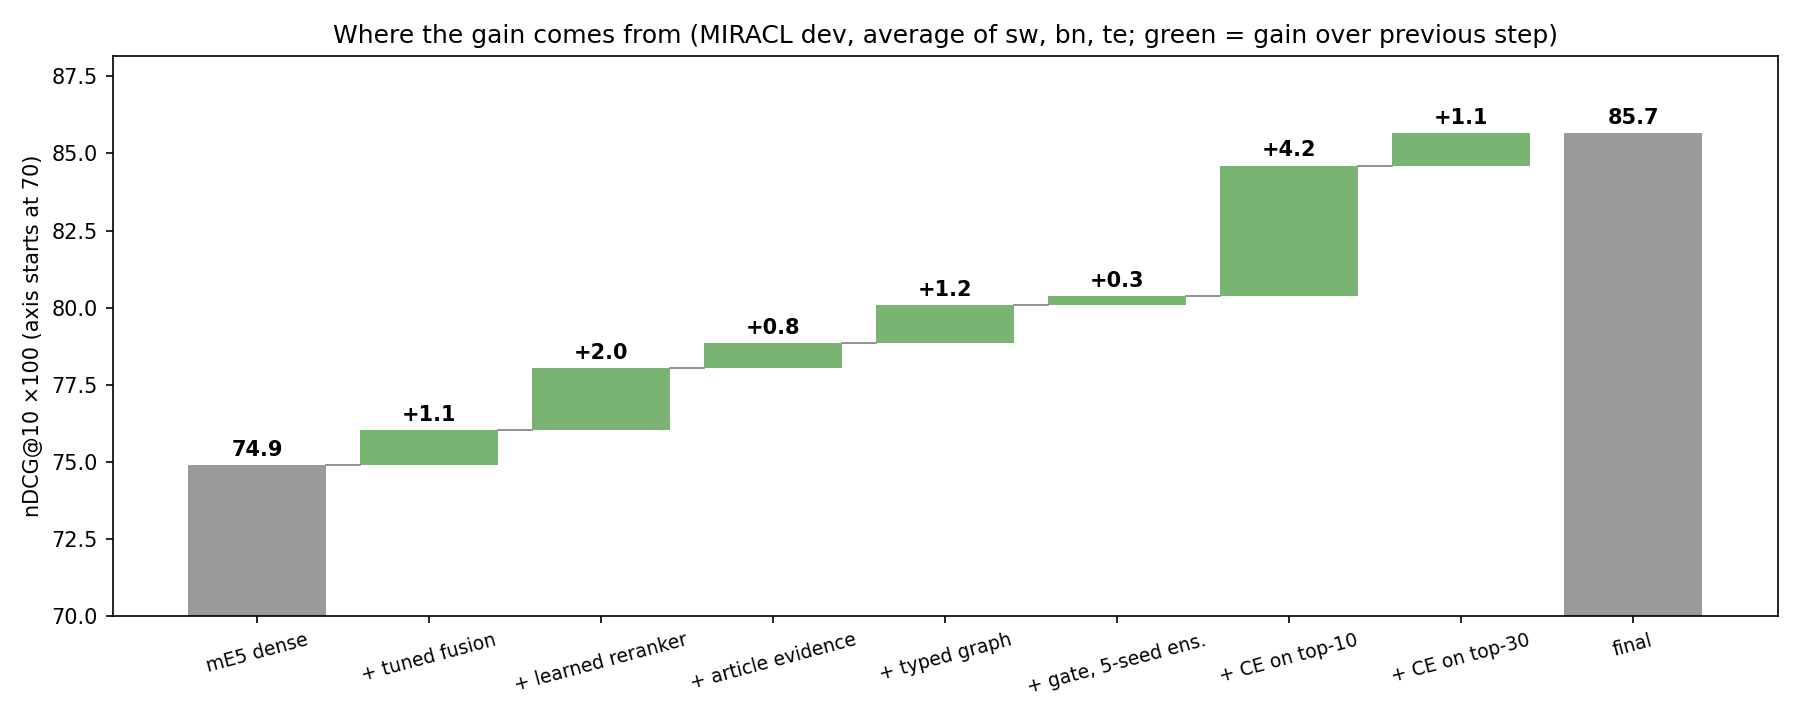

  plot: ndcg


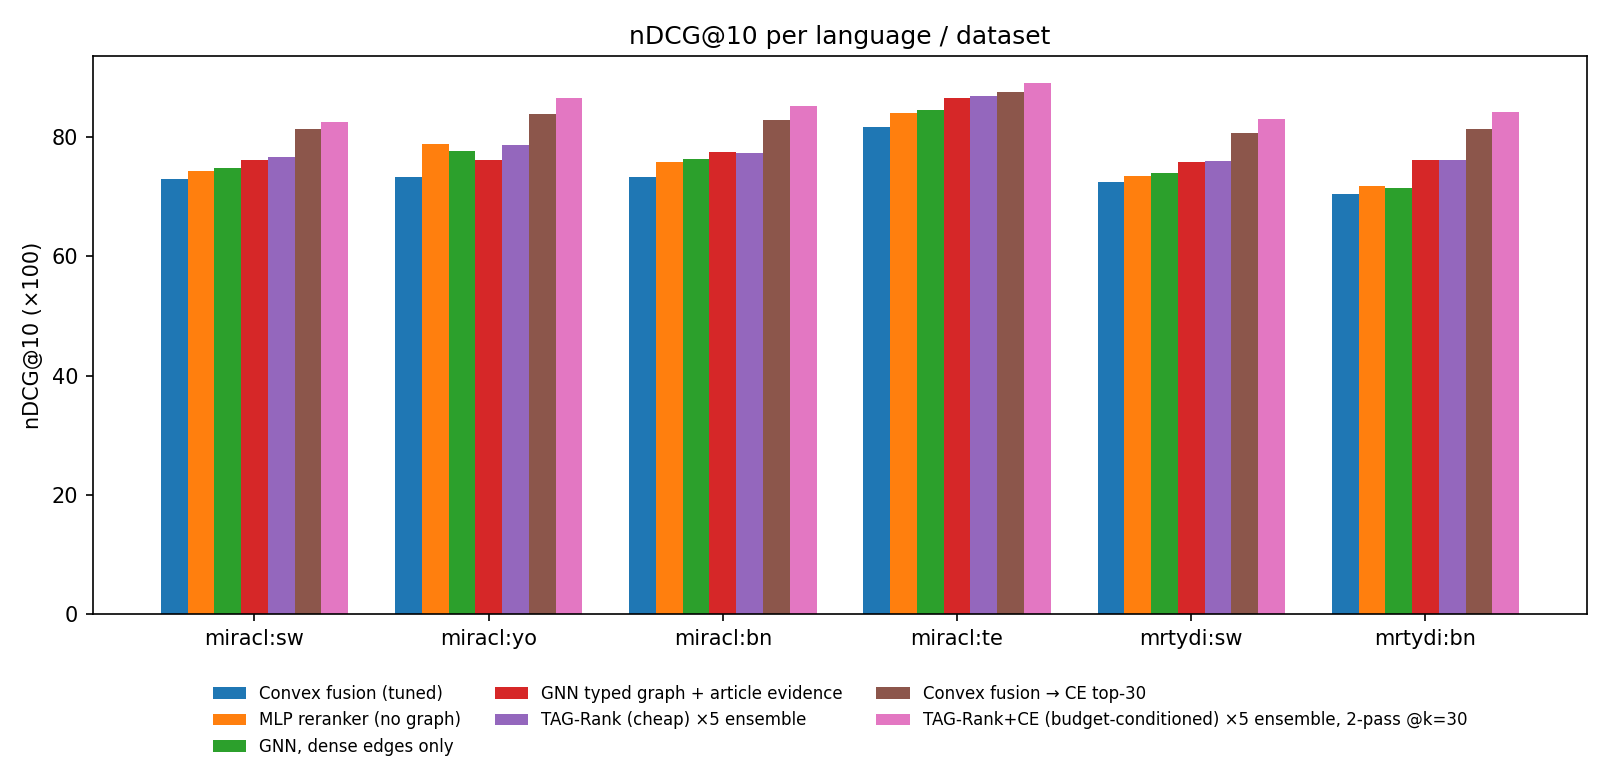

  plot: published


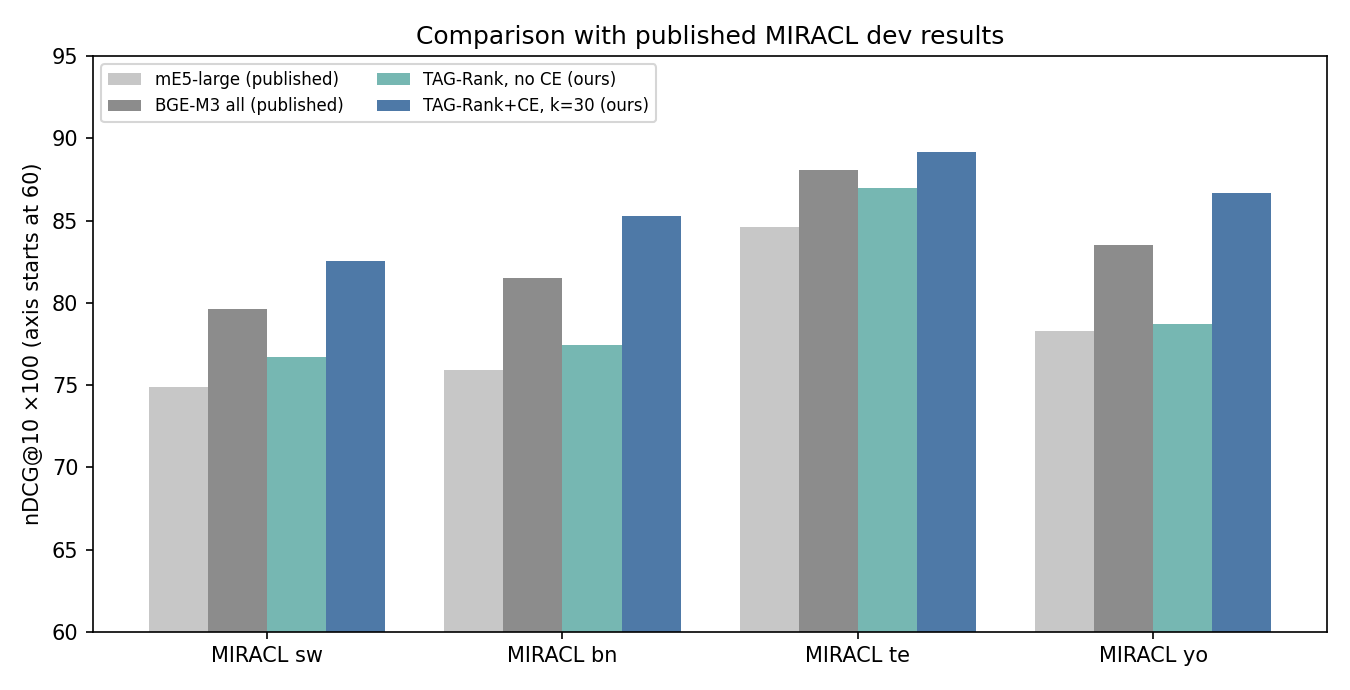

  plot: pareto


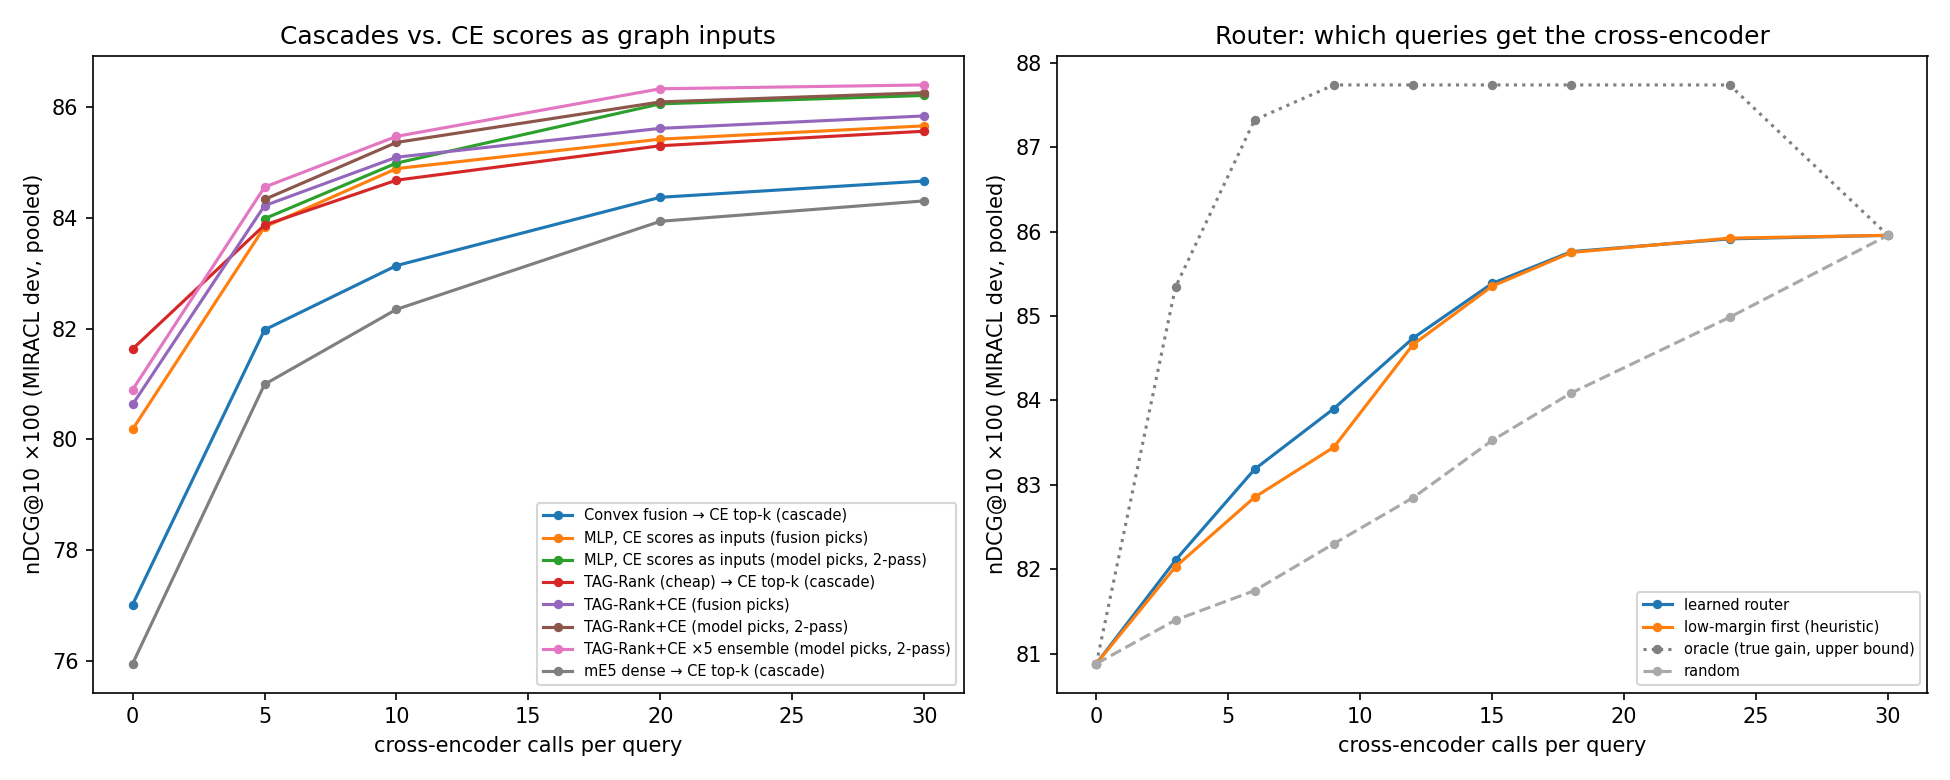

  plot: budget gain


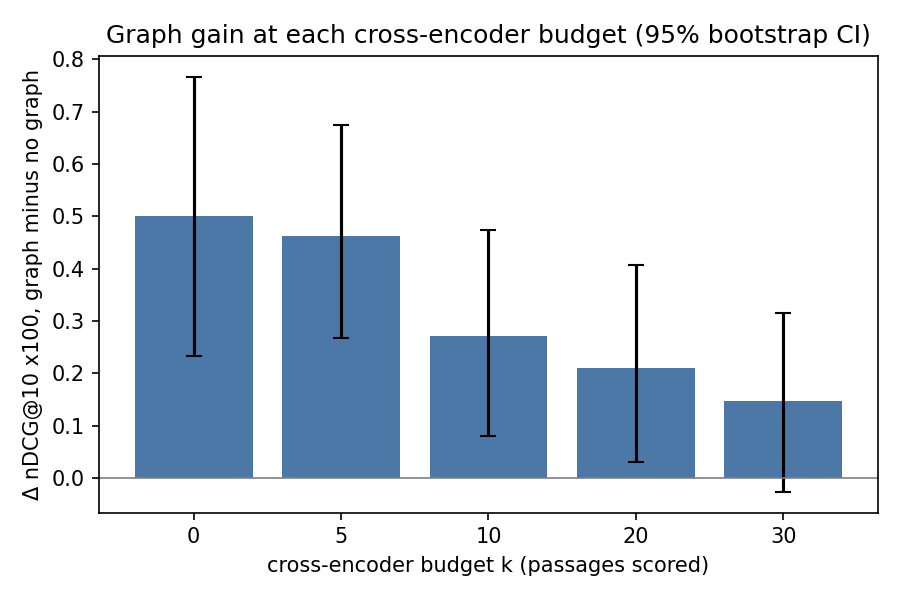

  plot: homophily


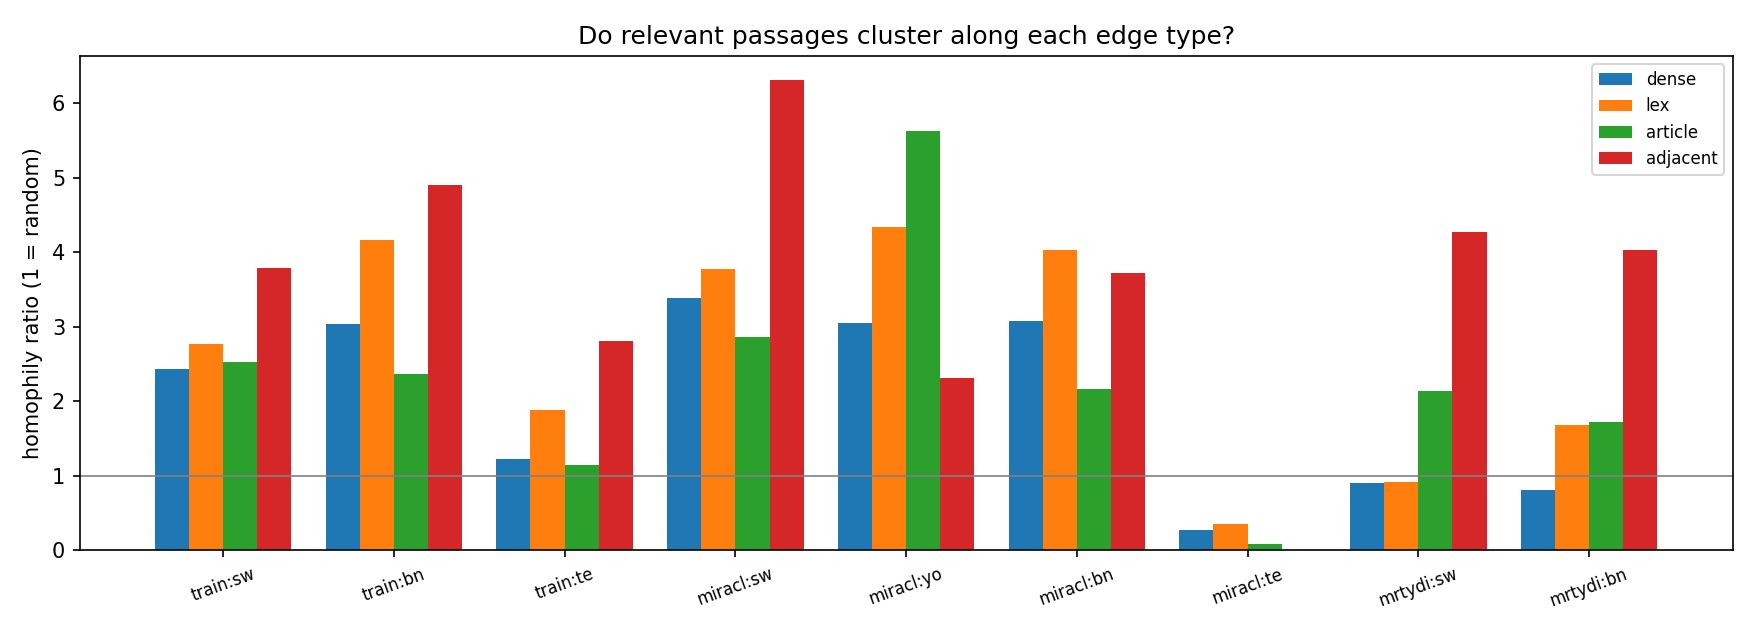

  plot: gar


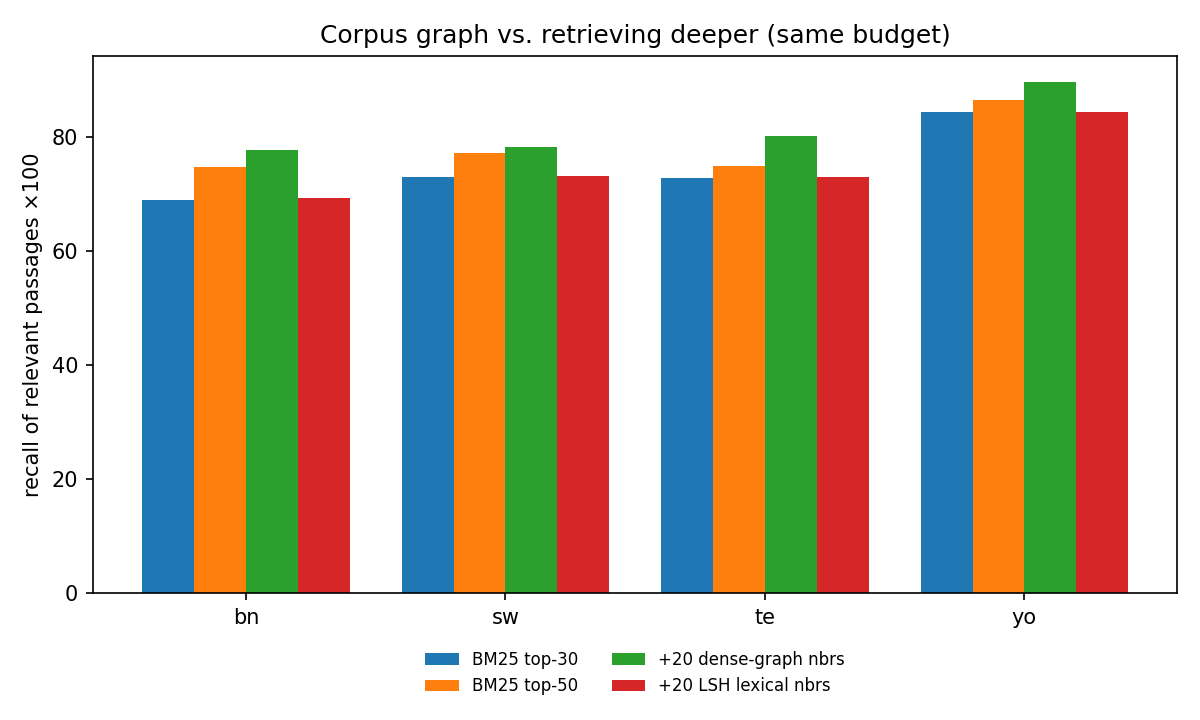

  plot: training


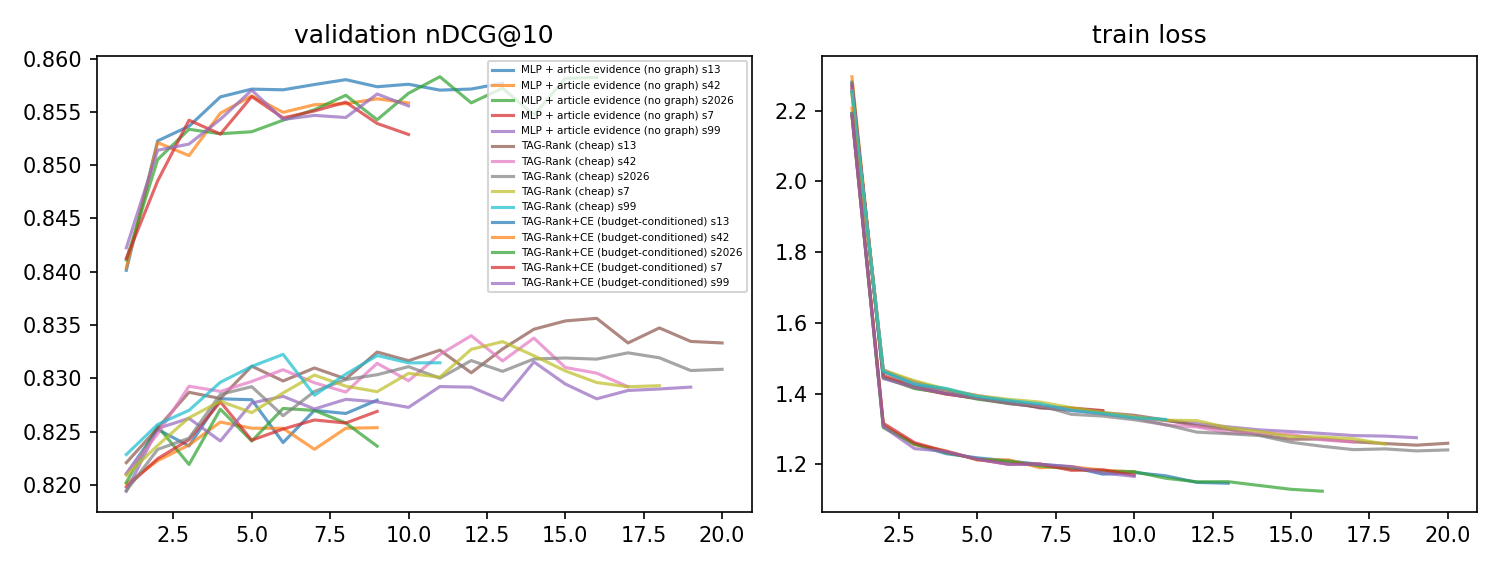

In [17]:
# published MIRACL dev numbers (BGE-M3 paper) for comparison
PUBLISHED = {"mE5-large (published)": {"sw": 74.9, "bn": 75.9, "te": 84.6, "yo": 78.3},
             "BGE-M3 all (published)": {"sw": 79.6, "bn": 81.5, "te": 88.1, "yo": 83.5}}

def safe_plot(fn, name, fname):
    try:
        fn(); log("  plot:", name)
    except Exception as e:
        warn(f"plot {name} failed: {e!r}"); traceback.print_exc()
    finally:
        plt.close("all")
    show_img(os.path.join(PLOT_DIR, fname))

def plot_ndcg():
    t = TABLES["ndcg@10"][GROUP_ORDER] * 100
    show = [m for m in ["Convex fusion (tuned)", NOG, RUN1, GTYPED, ENS(MAIN), f"Convex fusion → CE top-{KMAX}", ENS2(KMAX)]
            if m in t.index]
    fig, ax = plt.subplots(figsize=(max(8, 1.8 * len(GROUP_ORDER)), 5.2))
    w = 0.8 / len(show)
    for i, m in enumerate(show):
        ax.bar(np.arange(len(GROUP_ORDER)) + i * w, t.loc[m].values, w, label=m)
    ax.set_xticks(np.arange(len(GROUP_ORDER)) + 0.4 - w / 2); ax.set_xticklabels(GROUP_ORDER)
    ax.set_ylabel("nDCG@10 (×100)"); ax.set_title("nDCG@10 per language / dataset")
    ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, "ndcg_per_language.png"), dpi=150)

def plot_pareto():
    pdf = pd.DataFrame(PARETO)
    if not len(pdf): return
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    for ax, routers in zip(axes, [False, True]):
        sub = pdf[pdf["policy"].str.startswith("router") == routers]
        for pol, g in sub.groupby("policy"):
            if "oracle" in pol: style = dict(ls=":", color="grey")
            elif "random" in pol: style = dict(ls="--", color="darkgrey")
            else: style = {}
            g = g.sort_values("ce_calls_per_query")
            ax.plot(g["ce_calls_per_query"], g["ndcg@10"] * 100, marker="o", ms=3.5, label=pol.replace("router: ", ""), **style)
        ax.set_xlabel("cross-encoder calls per query"); ax.legend(fontsize=7, loc="lower right")
        ax.set_title("Router: which queries get the cross-encoder" if routers else "Cascades vs. CE scores as graph inputs")
    for ax in axes: ax.set_ylabel("nDCG@10 ×100 (MIRACL dev, pooled)")
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, "cost_quality_pareto.png"), dpi=150)

def plot_budget_gain():
    rows = []
    tr = [g for g in GROUP_ORDER if g.startswith("miracl") and g.split(":")[1] in CFG.train_langs]
    rs = np.random.RandomState(0)
    for k in CFG.budget_ks:
        a, b = f"{GB} @k={k}", f"{MB} @k={k}"
        if a not in METHOD_SCORES or b not in METHOD_SCORES: continue
        d = (pd.concat([METHOD_SCORES[a][g]["ndcg@10"] for g in tr]) -
             pd.concat([METHOD_SCORES[b][g]["ndcg@10"] for g in tr])).values * 100
        boots = [rs.choice(d, len(d)).mean() for _ in range(1000)]
        rows.append((k, d.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)))
    if not rows: return
    k, m, lo, hi = map(np.array, zip(*rows))
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar([str(x) for x in k], m, color="#4C78A8", yerr=[m - lo, hi - m], capsize=4)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel("cross-encoder budget k (passages scored)"); ax.set_ylabel("Δ nDCG@10 x100, graph minus no graph")
    ax.set_title("Graph gain at each cross-encoder budget (95% bootstrap CI)")
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, "graph_gain_vs_budget.png"), dpi=150)
    RESULTS["graph_gain_vs_budget"] = [{"k": int(a), "mean": float(b), "ci_lo": float(c), "ci_hi": float(d)} for a, b, c, d in rows]

def plot_homophily():
    H = pd.DataFrame({g: {t: v[t]["homophily_ratio"] for t in EDGE_TYPES} for g, v in HOMOPHILY.items()}).T
    fig, ax = plt.subplots(figsize=(max(7, 1.3 * len(H)), 4.2))
    w = 0.8 / len(EDGE_TYPES)
    for i, t in enumerate(EDGE_TYPES):
        ax.bar(np.arange(len(H)) + i * w, H[t].values, w, label=t)
    ax.axhline(1, color="grey", lw=0.8)
    ax.set_xticks(np.arange(len(H)) + 0.4 - w / 2); ax.set_xticklabels(H.index, rotation=20, fontsize=8)
    ax.set_ylabel("homophily ratio (1 = random)"); ax.set_title("Do relevant passages cluster along each edge type?")
    ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, "homophily.png"), dpi=150)

def plot_gar():
    if not len(GAR_DF): return
    T = GAR_DF.drop(columns=["key"]).groupby("lang").mean() * 100
    fig, ax = plt.subplots(figsize=(8, 4.8))
    w = 0.8 / len(T.columns)
    for i, c in enumerate(T.columns):
        ax.bar(np.arange(len(T)) + i * w, T[c].values, w, label=c)
    ax.set_xticks(np.arange(len(T)) + 0.4 - w / 2); ax.set_xticklabels(T.index)
    ax.set_ylabel("recall of relevant passages ×100"); ax.set_title("Corpus graph vs. retrieving deeper (same budget)")
    ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, "gar_recall_study.png"), dpi=150)

def plot_training():
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for name in [MART, MAIN, GB]:
        for s, h in HISTORY.get(name, {}).items():
            axes[0].plot([x["epoch"] for x in h], [x["val_ndcg@10"] for x in h], label=f"{name} s{s}", alpha=.7)
            axes[1].plot([x["epoch"] for x in h], [x["loss"] for x in h], alpha=.7)
    axes[0].set_title("validation nDCG@10"); axes[1].set_title("train loss"); axes[0].legend(fontsize=5)
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, "training_curves.png"), dpi=150)

def plot_bridge():
    t = TABLES["ndcg@10"]["MIRACL avg (trained langs)"] * 100
    steps = [("mE5 dense", "mE5 dense"), ("+ tuned fusion", "Convex fusion (tuned)"), ("+ learned reranker", NOG),
             ("+ article evidence", MART), ("+ typed graph", GTYPED), (f"+ gate, {len(CFG.seeds)}-seed ens.", ENS(MAIN)),
             (f"+ CE on top-{KMID}", ENS2(KMID)), (f"+ CE on top-{KMAX}", ENS2(KMAX))]
    steps = [(l, m) for l, m in steps if m in t.index and not pd.isna(t[m])]
    vals = [float(t[m]) for _, m in steps]
    lo = 5 * math.floor((min(vals) - 3) / 5)
    fig, ax = plt.subplots(figsize=(12, 4.8))
    labels = [l for l, _ in steps] + ["final"]
    for i, v in enumerate(vals):
        if i == 0:
            ax.bar(i, v - lo, bottom=lo, color="#9a9a9a"); ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontweight="bold")
        else:
            d = v - vals[i - 1]
            ax.bar(i, abs(d), bottom=min(v, vals[i - 1]), color="#59a14f" if d >= 0 else "#e15759", alpha=0.8)
            ax.text(i, max(v, vals[i - 1]) + 0.3, f"{d:+.1f}", ha="center", fontweight="bold")
            ax.plot([i - 0.6, i - 0.4], [vals[i - 1]] * 2, color="grey", lw=0.8)
    n = len(vals)
    ax.bar(n, vals[-1] - lo, bottom=lo, color="#9a9a9a"); ax.text(n, vals[-1] + 0.3, f"{vals[-1]:.1f}", ha="center", fontweight="bold")
    ax.set_xticks(range(n + 1)); ax.set_xticklabels(labels, rotation=15, fontsize=9)
    ax.set_ylim(lo, max(vals) + 2.5)
    ax.set_ylabel(f"nDCG@10 ×100 (axis starts at {lo})")
    ax.set_title("Where the gain comes from (MIRACL dev, average of sw, bn, te; green = gain over previous step)")
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, "gain_bridge.png"), dpi=150)

def plot_published():
    langs = [l for l in ["sw", "bn", "te", "yo"] if f"miracl:{l}" in GROUP_ORDER]
    t = TABLES["ndcg@10"] * 100
    series = dict(PUBLISHED)
    if ENS(MAIN) in t.index: series["TAG-Rank, no CE (ours)"] = {l: t.loc[ENS(MAIN), f"miracl:{l}"] for l in langs}
    if ENS2(KMAX) in t.index: series[f"TAG-Rank+CE, k={KMAX} (ours)"] = {l: t.loc[ENS2(KMAX), f"miracl:{l}"] for l in langs}
    fig, ax = plt.subplots(figsize=(9, 4.6))
    w = 0.8 / len(series)
    for i, (nm, d) in enumerate(series.items()):
        ax.bar(np.arange(len(langs)) + i * w, [d.get(l, np.nan) for l in langs], w, label=nm,
               color=["#c7c7c7", "#8c8c8c", "#76b7b2", "#4e79a7"][i % 4])
    ax.set_xticks(np.arange(len(langs)) + 0.4 - w / 2); ax.set_xticklabels([f"MIRACL {l}" for l in langs])
    ax.set_ylim(60, 95); ax.set_ylabel("nDCG@10 ×100 (axis starts at 60)")
    ax.set_title("Comparison with published MIRACL dev results")
    ax.legend(fontsize=8, ncol=2, loc="upper left")
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, "published_comparison.png"), dpi=150)

for fn, name, fname in [(plot_bridge, "bridge", "gain_bridge.png"), (plot_ndcg, "ndcg", "ndcg_per_language.png"),
                        (plot_published, "published", "published_comparison.png"),
                        (plot_pareto, "pareto", "cost_quality_pareto.png"), (plot_budget_gain, "budget gain", "graph_gain_vs_budget.png"),
                        (plot_homophily, "homophily", "homophily.png"), (plot_gar, "gar", "gar_recall_study.png"),
                        (plot_training, "training", "training_curves.png")]:
    safe_plot(fn, name, fname)

## 14. Findings and export
`findings.md` lists every conclusion with the numbers from this run and `summary.md` has all the tables.
Everything is zipped into `results.zip` in the output folder.

In [18]:
def jsonable(x):
    if isinstance(x, dict): return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, set)): return [jsonable(v) for v in x]
    if isinstance(x, (np.floating, float)):
        return None if math.isnan(float(x)) or math.isinf(float(x)) else float(x)
    if isinstance(x, np.integer): return int(x)
    if isinstance(x, np.bool_): return bool(x)
    return x

def md_table(df, digits=1, index=True):
    df = df.copy()
    cols = ([df.index.name or ""] if index else []) + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        vals = [f"{v:.{digits}f}" if isinstance(v, (float, np.floating)) and not pd.isna(v) else ("" if pd.isna(v) else str(v))
                for v in row.values]
        lines.append("| " + " | ".join(([str(idx)] if index else []) + vals) + " |")
    return "\n".join(lines)

SYSTEMS = {"TAG-Rank, no cross-encoder": ENS(MAIN), f"TAG-Rank+CE, CE on top-{KMID}": ENS2(KMID),
           f"TAG-Rank+CE, CE on top-{KMAX}": ENS2(KMAX)}
def tval(m, g="MIRACL avg (trained langs)"):
    try: return float(TABLES["ndcg@10"].loc[m, g]) * 100
    except Exception: return float("nan")
RESULTS["systems"] = {k: {"method": v, "miracl_trained_avg": tval(v), **{g: tval(v, g) for g in GROUP_ORDER}}
                      for k, v in SYSTEMS.items()}
RESULTS["tables"] = {m: {k: {kk: (None if pd.isna(vv) else round(float(vv), 5)) for kk, vv in row.items()}
                         for k, row in t.to_dict(orient="index").items()} for m, t in TABLES.items()}
RESULTS["seed_std_ndcg@10"] = seed_std
RESULTS["key_comparisons"] = KEY.to_dict(orient="records") if len(KEY) else []
RESULTS["n_queries"] = {g: len(v) for g, v in EVAL_GROUPS.items()}
RESULTS["n_train_queries"] = {"fit": len(FIT_RECS), "val": len(VAL_RECS)}
RESULTS["variants"] = {n: {k: (sorted(v) if isinstance(v, set) else v) for k, v in c.items()} for n, c in VARIANTS.items()}
RESULTS["total_minutes"] = round((time.time() - _T0) / 60, 1)
RESULTS["published_reference"] = {
    "note": "MIRACL dev nDCG@10 x100. mE5-base: mE5 technical report; mE5-large and BGE-M3 (dense+sparse+multivec): BGE-M3 paper",
    "mE5-base": {"sw": 71.1, "bn": 70.2, "te": 75.2},
    "mE5-large": {"sw": 74.9, "bn": 75.9, "te": 84.6, "yo": 78.3},
    "BGE-M3 all": {"sw": 79.6, "bn": 81.5, "te": 88.1, "yo": 83.5}}
with open(os.path.join(RES_DIR, "results.json"), "w") as f:
    json.dump(jsonable(RESULTS), f, indent=1, ensure_ascii=False)
per_q = pd.concat([df.assign(method=m, group=g) for m, d in METHOD_SCORES.items() for g, df in d.items()])
per_q.reset_index().to_csv(os.path.join(RES_DIR, "per_query_metrics.csv.gz"), index=False)


# findings.md: every conclusion written out with the numbers from this run
def kp(label, group="MIRACL trained langs (pooled)"):
    if not len(KEY): return None
    r = KEY[(KEY["comparison"] == label) & (KEY["group"] == group)]
    return None if r.empty else r.iloc[0]
def fmt_kp(label, group="MIRACL trained langs (pooled)"):
    r = kp(label, group)
    return "n/a" if r is None else f"{r['delta_ndcg@10']:+.2f} (p = {r['p_wilcoxon']:.3g}, {int(r['wins'])} wins / {int(r['losses'])} losses)"
def holm_count(label):
    if not len(KEY): return "n/a"
    r = KEY[(KEY["comparison"] == label) & KEY["group"].str.startswith("miracl")]
    tr = r[r["group"].str.split(":").str[1].isin(CFG.train_langs)]
    return f"{int((tr['p_holm'] < 0.05).sum())} of {len(tr)} training languages significant after Holm"
F = []
try:
    T = TABLES["ndcg@10"] * 100; A = "MIRACL avg (trained langs)"
    F.append("# Findings (generated from this run)\n")
    F.append(f"nDCG@10 ×100 on MIRACL dev, averaged over {', '.join(CFG.train_langs)} unless stated. p-values: paired Wilcoxon over queries.\n")
    F.append("## RQ1: First-stage retrieval")
    F.append(f"- Dense mE5 {T.loc['mE5 dense', A]:.1f} vs BM25 {T.loc['BM25', A]:.1f}; equal-weight RRF {T.loc['RRF (equal weights)', A]:.1f} "
             f"(worse than dense alone); tuned convex fusion (λ = {LAM}) {T.loc['Convex fusion (tuned)', A]:.1f}.")
    F.append(f"- A learned reranker without a graph reaches {T.loc[NOG, A]:.1f}: {fmt_kp('RQ1 learned reranker vs tuned fusion')} over tuned fusion.")
    F.append("\n## RQ2: Does the graph help, and which edges?")
    F.append(f"- Dense-similarity edges only: {fmt_kp('RQ2 dense-only graph vs no graph')} over the no-graph MLP.")
    F.append(f"- Typed graph vs the same features without a graph: {fmt_kp('RQ2 typed graph vs no graph (same features)')}; "
             f"{holm_count('RQ2 typed graph vs no graph (same features)')}.")
    for e in ["dense edges", "lexical edges", "article/adjacent edges"]:
        F.append(f"- Removing {e}: {fmt_kp('RQ2 ablation: remove ' + e)} (3 seeds).")
    F.append("\n## RQ3: Article evidence and transfer to Yorùbá")
    F.append(f"- Article evidence without a graph: {fmt_kp('RQ3 article evidence (no graph)')}.")
    F.append(f"- Passages per article: " + ", ".join(f"{c} {v:.2f}" for c, v in PPA.items()) +
             f"; gate threshold {PPA_THRESHOLD:.2f} → article channel off for " +
             (", ".join(c for c, on in GATE.items() if not on) or "none") + ".")
    if "miracl:yo" in GROUP_ORDER:
        F.append(f"- Yorùbá, gate on vs off (same model): {fmt_kp('RQ3 gate on vs off (same model)', 'miracl:yo')}. "
                 f"Yorùbá nDCG@10: no-graph MLP {T.loc[NOG, 'miracl:yo']:.1f}, TAG-Rank {T.loc[MAIN, 'miracl:yo']:.1f}, "
                 f"ungated {T.loc[f'{MAIN} [no gate]', 'miracl:yo']:.1f}.")
    F.append(f"- Structure-aware training + gate on training languages: {fmt_kp('RQ3 structure-aware training + gate')}.")
    F.append(f"- {len(CFG.seeds)}-seed ensemble: {fmt_kp('5-seed ensemble vs single model')}. "
             f"Final cheap model vs no-graph MLP: {fmt_kp('Final cheap model vs no-graph reranker')}.")
    F.append("\n## RQ4: Making the cross-encoder cheaper")
    for k in CFG.budget_ks:
        F.append(f"- Graph gain {'without CE (k = 0)' if k == 0 else f'with CE scores for the top-{k}'}: "
                 f"{fmt_kp(f'RQ4 graph effect at CE budget k={k}')}.")
    for k in [k for k in CFG.budget_ks if k > 0]:
        F.append(f"- CE scores as graph inputs vs fusion cascade, both on top-{k}: {fmt_kp(f'RQ4 CE as graph input vs cascade, k={k}')}.")
    F.append(f"- TAG-Rank+CE scoring {KMID} passages vs fusion cascade scoring {KMAX}: "
             f"{fmt_kp(f'RQ4 TAG-Rank+CE on {KMID} vs fusion cascade on {KMAX}')}.")
    if ROUTER:
        F.append(f"- Router: Spearman correlation of predicted vs true CE gain on MIRACL dev = {ROUTER['spearman_pred_vs_true_gain_dev']:.2f}.")
    F.append("\n## Final systems vs published results (MIRACL dev nDCG@10 ×100)")
    langs = [l for l in ["sw", "bn", "te", "yo"] if f"miracl:{l}" in GROUP_ORDER]
    F.append("| system | " + " | ".join(langs) + " |"); F.append("|---|" + "---|" * len(langs))
    for nm, d in PUBLISHED.items():
        F.append(f"| {nm} | " + " | ".join(f"{d.get(l, float('nan')):.1f}" for l in langs) + " |")
    for k, v in SYSTEMS.items():
        F.append(f"| {k} (ours) | " + " | ".join(f"{tval(v, f'miracl:{l}'):.1f}" for l in langs) + " |")
    F.append("\n## RQ5: Why the graph helps")
    if HOMOPHILY:
        F.append("- Homophily ratio (1 = random) per edge type: " + "; ".join(
            f"{g}: " + ", ".join(f"{t} {v[t]['homophily_ratio']:.1f}" for t in EDGE_TYPES if not math.isnan(v[t]["homophily_ratio"]))
            for g, v in HOMOPHILY.items()))
    if BUCKETS.get("relevant_in_pool"):
        F.append("- Graph gain by number of relevant passages in the pool: " + ", ".join(
            f"{b}: {v['mean']:+.2f} (n={v['count']})" for b, v in BUCKETS["relevant_in_pool"].items()))
    F.append(f"\nRuntime {RESULTS['total_minutes']} min; warnings: {len(RESULTS['warnings'])}.")
except Exception as e:
    warn(f"findings.md failed: {e!r}"); traceback.print_exc()
with open(os.path.join(RES_DIR, "findings.md"), "w") as fh:
    fh.write("\n".join(F) + "\n")
show_md("\n".join(F))

try:
    md = [f"# Final run, all tables\n\nTotal runtime {RESULTS['total_minutes']} min, warnings: {len(RESULTS['warnings'])}\n",
          "## nDCG@10 ×100\n", md_table(TABLES["ndcg@10"] * 100), "\n## MRR@100 ×100\n", md_table(TABLES["mrr@100"] * 100)]
    if len(KEY):
        kt = KEY[["comparison", "group", "delta_ndcg@10", "p_wilcoxon", "p_holm", "wins", "losses"]].copy()
        md += ["\n## Key comparisons (Δ nDCG@10 ×100, Wilcoxon, Holm over MIRACL languages)\n", md_table(kt, 3, index=False)]
    if PARETO:
        md += ["\n## Cost vs. quality (MIRACL dev pooled)\n",
               md_table(pd.DataFrame(PARETO).pivot_table(index="policy", columns="ce_calls_per_query", values="ndcg@10") * 100)]
    if HOMOPHILY:
        md += ["\n## Homophily ratio\n", md_table(pd.DataFrame({g: {t: v[t]["homophily_ratio"] for t in EDGE_TYPES}
                                                                  for g, v in HOMOPHILY.items()}).T, 2)]
    if len(GAR_DF):
        md += ["\n## GAR recall study (×100)\n", md_table(GAR_TABLE)]
    if LSH_STATS:
        md += ["\n## Spark MinHash-LSH\n", md_table(pd.DataFrame(LSH_STATS).T, 0)]
    if PROFILE:
        md += ["\n## Spark corpus profile\n", md_table(pd.DataFrame(PROFILE).T, 3)]
    md += ["\n## Timings (s)\n", "\n".join(f"- {k}: {v}" for k, v in RESULTS["timings_sec"].items())]
    with open(os.path.join(RES_DIR, "summary.md"), "w") as fh:
        fh.write("\n".join(md) + "\n")
except Exception as e:
    warn(f"summary.md failed: {e!r}"); traceback.print_exc()

# zip the results folder so it can be downloaded in one go
zpath = os.path.join(CFG.work_dir, "results.zip")
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for r, _, fs in os.walk(RES_DIR):
        for f in fs:
            z.write(os.path.join(r, f), os.path.relpath(os.path.join(r, f), CFG.work_dir))
shutil.rmtree(os.path.join(CFG.work_dir, "lsh_graph"), ignore_errors=True)
log(f"\nDONE in {RESULTS['total_minutes']} min, results saved to {zpath}")
log("Warnings:", RESULTS["warnings"] or "none")

# Findings (generated from this run)

nDCG@10 ×100 on MIRACL dev, averaged over sw, bn, te unless stated. p-values: paired Wilcoxon over queries.

## RQ1: First-stage retrieval
- Dense mE5 74.9 vs BM25 45.8; equal-weight RRF 64.2 (worse than dense alone); tuned convex fusion (λ = 0.1) 76.0.
- A learned reranker without a graph reaches 78.0: +2.05 (p = 6.32e-14, 450 wins / 268 losses) over tuned fusion.

## RQ2: Does the graph help, and which edges?
- Dense-similarity edges only: +0.58 (p = 5.2e-05, 382 wins / 276 losses) over the no-graph MLP.
- Typed graph vs the same features without a graph: +1.23 (p = 3.52e-11, 444 wins / 282 losses); 3 of 3 training languages significant after Holm.
- Removing dense edges: -0.80 (p = 0.000392, 361 wins / 407 losses) (3 seeds).
- Removing lexical edges: -0.15 (p = 0.0779, 325 wins / 383 losses) (3 seeds).
- Removing article/adjacent edges: -0.18 (p = 0.255, 341 wins / 357 losses) (3 seeds).

## RQ3: Article evidence and transfer to Yorùbá
- Article evidence without a graph: +0.95 (p = 0.00196, 409 wins / 341 losses).
- Passages per article: miracl:sw 2.76, miracl:yo 1.48, miracl:bn 4.66, miracl:te 7.81, mrtydi:sw 2.86, mrtydi:bn 4.77; gate threshold 2.21 → article channel off for miracl:yo.
- Yorùbá, gate on vs off (same model): +2.55 (p = 0.02, 39 wins / 23 losses). Yorùbá nDCG@10: no-graph MLP 78.9, TAG-Rank 77.6, ungated 75.1.
- Structure-aware training + gate on training languages: -0.11 (p = 0.262, 308 wins / 338 losses).
- 5-seed ensemble: +0.45 (p = 3.63e-05, 367 wins / 278 losses). Final cheap model vs no-graph MLP: +2.52 (p = 3.25e-17, 444 wins / 257 losses).

## RQ4: Making the cross-encoder cheaper
- Graph gain without CE (k = 0): +0.50 (p = 9.95e-05, 377 wins / 276 losses).
- Graph gain with CE scores for the top-5: +0.46 (p = 4.37e-08, 333 wins / 203 losses).
- Graph gain with CE scores for the top-10: +0.27 (p = 0.00087, 283 wins / 203 losses).
- Graph gain with CE scores for the top-20: +0.21 (p = 0.017, 257 wins / 219 losses).
- Graph gain with CE scores for the top-30: +0.15 (p = 0.0793, 257 wins / 239 losses).
- CE scores as graph inputs vs fusion cascade, both on top-5: +2.24 (p = 1.74e-18, 381 wins / 202 losses).
- CE scores as graph inputs vs fusion cascade, both on top-10: +1.94 (p = 5.05e-14, 335 wins / 201 losses).
- CE scores as graph inputs vs fusion cascade, both on top-20: +1.26 (p = 5.19e-08, 331 wins / 213 losses).
- CE scores as graph inputs vs fusion cascade, both on top-30: +1.19 (p = 1.09e-06, 329 wins / 227 losses).
- TAG-Rank+CE scoring 10 passages vs fusion cascade scoring 30: +0.78 (p = 0.00219, 257 wins / 188 losses).
- Router: Spearman correlation of predicted vs true CE gain on MIRACL dev = 0.28.

## Final systems vs published results (MIRACL dev nDCG@10 ×100)
| system | sw | bn | te | yo |
|---|---|---|---|---|
| mE5-large (published) | 74.9 | 75.9 | 84.6 | 78.3 |
| BGE-M3 all (published) | 79.6 | 81.5 | 88.1 | 83.5 |
| TAG-Rank, no cross-encoder (ours) | 76.7 | 77.4 | 87.0 | 78.7 |
| TAG-Rank+CE, CE on top-10 (ours) | 80.9 | 83.9 | 88.9 | 85.0 |
| TAG-Rank+CE, CE on top-30 (ours) | 82.5 | 85.3 | 89.2 | 86.7 |

## RQ5: Why the graph helps
- Homophily ratio (1 = random) per edge type: train:sw: dense 2.4, lex 2.8, article 2.5, adjacent 3.8; train:bn: dense 3.0, lex 4.2, article 2.4, adjacent 4.9; train:te: dense 1.2, lex 1.9, article 1.1, adjacent 2.8; miracl:sw: dense 3.4, lex 3.8, article 2.9, adjacent 6.3; miracl:yo: dense 3.1, lex 4.3, article 5.6, adjacent 2.3; miracl:bn: dense 3.1, lex 4.0, article 2.2, adjacent 3.7; miracl:te: dense 0.3, lex 0.4, article 0.1, adjacent 0.0; mrtydi:sw: dense 0.9, lex 0.9, article 2.1, adjacent 4.3; mrtydi:bn: dense 0.8, lex 1.7, article 1.7, adjacent 4.0
- Graph gain by number of relevant passages in the pool: 0: +0.00 (n=18), 1: +1.06 (n=1336), 2: +1.44 (n=265), 3+: +1.69 (n=221)

Runtime 146.2 min; warnings: 0.


DONE in 146.2 min, results saved to /kaggle/working/results.zip
Warnings: none
